# NB05h — Final Comprehensive Evaluation: Topology-Guided Ensemble (V5+V6+V7)
**FSDF-UCA-Net: SliceAttentionGate + TumorAwareHead + scSE + Focal Tversky**  
**Topology-Guided Fusion | 80/20 Split | 42 Validation Cases | TTA + PP**

Pipeline: V5 seed (thr=0.50) + V5+V6+V7 triple growth (thr=0.35, w=0.30/0.40/0.30)  
Keep only growth blobs touching V5 seed; if V5 blind → full rescue

Metrics: Dice, IoU, HD95, ASSD, Sensitivity, Precision  
10 thesis figures at 300 DPI

In [1]:
import torch, torch.nn as nn, torch.nn.functional as F
import numpy as np, json, time, csv, gc, warnings
import segmentation_models_pytorch as smp
from pathlib import Path
from collections import defaultdict
from scipy.ndimage import gaussian_filter, label as scipy_label, generate_binary_structure
from scipy.ndimage import distance_transform_edt, binary_erosion
import matplotlib; matplotlib.use('Agg')
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

Device: cuda


In [2]:
OUTPUT_DIR = Path(r"D:\fsdf_uca_kits\outputs")
CKPT_DIR = OUTPUT_DIR / "checkpoints_80_20"
ROI_NNUNET_DIR = OUTPUT_DIR / "kidney_rois_nnunet_80_20"
PREPROC_DIR = OUTPUT_DIR / "preprocessed"
STATS_DIR = OUTPUT_DIR / "stats"
RESULTS_DIR = OUTPUT_DIR / "results_80_20"
FIG_DIR = OUTPUT_DIR / "figures" / "nb05h_final"
for d in [RESULTS_DIR, FIG_DIR]: d.mkdir(parents=True, exist_ok=True)
IMG_SIZE = 256; SLICE_CONTEXT = 7; NUM_CLASSES = 3
FUSE_CHANNELS = 48; ENCODER = 'efficientnet-b4'
ANOMALY_CASES = {'case_00208'}
# Topology fusion config (best from sweep)
SEED_THR = 0.50; GROWTH_THR = 0.35; W5, W6, W7 = 0.30, 0.40, 0.30
plt.rcParams.update({'font.size':12,'figure.dpi':150,'savefig.dpi':300,'savefig.bbox':'tight'})
print("Config: Topology fusion V5 seed + triple growth")

Config: Topology fusion V5 seed + triple growth


In [3]:
with open(STATS_DIR / "fold_splits_80_20.json") as f:
    splits = json.load(f)
val_cases = sorted(splits['folds']['fold_0']['val'])
with open(ROI_NNUNET_DIR / "roi_meta_all.json") as f:
    all_roi_metas = json.load(f)
val_rois = [r for r in all_roi_metas if r['case_name'] in set(val_cases)]
case_rois = defaultdict(list)
for r in val_rois: case_rois[r['case_name']].append(r)
cases_with_tumor = sorted(set(r['case_name'] for r in val_rois if r['has_tumor']))
case_info = {}
for cn in cases_with_tumor:
    label = np.load(PREPROC_DIR / cn / "label.npy")
    case_info[cn] = {'tvox': int((label==2).sum())}
print(f"Val: {len(cases_with_tumor)} cases with tumor, {len(val_rois)} ROIs")

Val: 42 cases with tumor, 99 ROIs


## 1. All Three Model Architectures

In [4]:
# ======== Shared modules ========
class ASPP(nn.Module):
    def __init__(self, ic, oc, rates=[1,6,12,18]):
        super().__init__()
        self.convs = nn.ModuleList([nn.Sequential(nn.Conv2d(ic,oc,3,padding=r,dilation=r),
            nn.InstanceNorm2d(oc),nn.ReLU(True)) for r in rates])
        self.gap = nn.Sequential(nn.AdaptiveAvgPool2d(1),nn.Conv2d(ic,oc,1),nn.ReLU(True))
        self.fuse = nn.Sequential(nn.Conv2d(oc*(len(rates)+1),oc,1),nn.InstanceNorm2d(oc),nn.ReLU(True))
    def forward(self, x):
        f=[c(x) for c in self.convs]
        f.append(F.interpolate(self.gap(x),size=x.shape[2:],mode='bilinear',align_corners=False))
        return self.fuse(torch.cat(f,dim=1))

class CBAM(nn.Module):
    def __init__(self, ch, red=8):
        super().__init__()
        r=ch//red
        self.ca=nn.Sequential(nn.AdaptiveAvgPool2d(1),nn.Flatten(),nn.Linear(ch,r),nn.ReLU(True),nn.Linear(r,ch))
        self.ca_max=nn.Sequential(nn.AdaptiveMaxPool2d(1),nn.Flatten(),nn.Linear(ch,r),nn.ReLU(True),nn.Linear(r,ch))
        self.sa=nn.Sequential(nn.Conv2d(2,1,7,padding=3),nn.Sigmoid()); self.spatial_attn=None
    def forward(self, x):
        x=x*torch.sigmoid(self.ca(x)+self.ca_max(x)).unsqueeze(-1).unsqueeze(-1)
        sa=self.sa(torch.cat([x.mean(1,keepdim=True),x.max(1,keepdim=True)[0]],1))
        self.spatial_attn=sa.detach(); return x*sa

class SliceAttentionGate(nn.Module):
    def __init__(self, ns=7, pk=7):
        super().__init__()
        self.num_slices=ns; self.spatial_conv=nn.Conv2d(2,1,pk,padding=pk//2,bias=True)
        self.slice_conv=nn.Conv2d(ns,ns,1,bias=True)
        nn.init.zeros_(self.spatial_conv.weight); nn.init.zeros_(self.spatial_conv.bias)
        nn.init.zeros_(self.slice_conv.weight); nn.init.zeros_(self.slice_conv.bias)
    def forward(self, x):
        sg=0.5+torch.sigmoid(self.spatial_conv(torch.cat([x.max(1,keepdim=True)[0],x.mean(1,keepdim=True)],1)))
        x=x*sg; return x*torch.softmax(self.slice_conv(x),dim=1)*self.num_slices

class TumorAwareHead(nn.Module):
    def __init__(self, ic):
        super().__init__()
        self.head=nn.Sequential(nn.Conv2d(ic,64,1),nn.ReLU(True),nn.Conv2d(64,1,1))
    def forward(self, x): return self.head(x)

# ======== V5: Baseline ========
class FSDFUCANetV5(nn.Module):
    def __init__(self, ic=7, nc=3, fc=48, en='efficientnet-b4'):
        super().__init__()
        self.spatial_unet=smp.UnetPlusPlus(encoder_name=en,encoder_weights='imagenet',in_channels=ic,classes=fc)
        self.aspp=ASPP(fc,fc); self.cbam=CBAM(fc)
        self.seg_head=nn.Sequential(nn.Conv2d(fc,fc,3,padding=1),nn.InstanceNorm2d(fc),nn.ReLU(True),nn.Conv2d(fc,nc,1))
        self.ds_head=nn.Conv2d(fc,nc,1)
        self.edl_head=nn.Sequential(nn.Conv2d(fc,fc,3,padding=1),nn.InstanceNorm2d(fc),nn.ReLU(True),nn.Conv2d(fc,nc,1),nn.Softplus())
    def forward(self, x, return_uncertainty=False):
        f=self.spatial_unet(x); fu=self.aspp(f); r=self.cbam(fu); logits=self.seg_head(r)
        if not return_uncertainty: return logits
        ev=self.edl_head(r); return logits, ev, NUM_CLASSES/(ev+1).sum(1,keepdim=True)

# ======== V6: + SliceGate + TumorHead ========
class FSDFUCANetV6(nn.Module):
    def __init__(self, ic=7, nc=3, fc=48, en='efficientnet-b4'):
        super().__init__()
        self.slice_gate=SliceAttentionGate(ic); self.spatial_unet=smp.UnetPlusPlus(encoder_name=en,encoder_weights='imagenet',in_channels=ic,classes=fc)
        self.aspp=ASPP(fc,fc); self.cbam=CBAM(fc)
        self.seg_head=nn.Sequential(nn.Conv2d(fc,fc,3,padding=1),nn.InstanceNorm2d(fc),nn.ReLU(True),nn.Conv2d(fc,nc,1))
        self.ds_head=nn.Conv2d(fc,nc,1)
        self.edl_head=nn.Sequential(nn.Conv2d(fc,fc,3,padding=1),nn.InstanceNorm2d(fc),nn.ReLU(True),nn.Conv2d(fc,nc,1),nn.Softplus())
        with torch.no_grad(): self.tumor_head=TumorAwareHead(self.spatial_unet.encoder(torch.zeros(1,ic,64,64))[-1].shape[1])
    def forward(self, x, return_uncertainty=False):
        x=self.slice_gate(x); ef=self.spatial_unet.encoder(x)
        sf=self.spatial_unet.segmentation_head(self.spatial_unet.decoder(ef))
        fu=self.aspp(sf); r=self.cbam(fu); logits=self.seg_head(r)
        out={"logits":logits,"tumor_logits":self.tumor_head(ef[-1])}
        if return_uncertainty:
            ev=self.edl_head(r); out["evidence"]=ev; out["uncertainty"]=NUM_CLASSES/(ev+1).sum(1,keepdim=True)
        return out

# ======== V7: + scSE decoder ========
class FSDFUCANetV7(nn.Module):
    def __init__(self, ic=7, nc=3, fc=48, en='efficientnet-b4'):
        super().__init__()
        self.slice_gate=SliceAttentionGate(ic); self.spatial_unet=smp.UnetPlusPlus(encoder_name=en,encoder_weights='imagenet',in_channels=ic,classes=fc,decoder_attention_type='scse')
        self.aspp=ASPP(fc,fc); self.cbam=CBAM(fc)
        self.seg_head=nn.Sequential(nn.Conv2d(fc,fc,3,padding=1),nn.InstanceNorm2d(fc),nn.ReLU(True),nn.Conv2d(fc,nc,1))
        self.ds_head=nn.Conv2d(fc,nc,1)
        self.edl_head=nn.Sequential(nn.Conv2d(fc,fc,3,padding=1),nn.InstanceNorm2d(fc),nn.ReLU(True),nn.Conv2d(fc,nc,1),nn.Softplus())
        with torch.no_grad(): self.tumor_head=TumorAwareHead(self.spatial_unet.encoder(torch.zeros(1,ic,64,64))[-1].shape[1])
    def forward(self, x, return_uncertainty=False):
        x=self.slice_gate(x); ef=self.spatial_unet.encoder(x)
        sf=self.spatial_unet.segmentation_head(self.spatial_unet.decoder(ef))
        fu=self.aspp(sf); r=self.cbam(fu); logits=self.seg_head(r)
        out={"logits":logits,"tumor_logits":self.tumor_head(ef[-1])}
        if return_uncertainty:
            ev=self.edl_head(r); out["evidence"]=ev; out["uncertainty"]=NUM_CLASSES/(ev+1).sum(1,keepdim=True)
        return out

# Load all 3 models
model_v5 = FSDFUCANetV5(SLICE_CONTEXT,NUM_CLASSES,FUSE_CHANNELS,ENCODER).to(device)
ck5 = torch.load(CKPT_DIR/'nb07d_fold0_best.pth',map_location=device,weights_only=False)
model_v5.load_state_dict(ck5['model_state']); model_v5.eval()
print(f"V5: ep{ck5['epoch']}, {sum(p.numel() for p in model_v5.parameters()):,} params")

model_v6 = FSDFUCANetV6(SLICE_CONTEXT,NUM_CLASSES,FUSE_CHANNELS,ENCODER).to(device)
ck6 = torch.load(CKPT_DIR/'nb07e_fold0_best.pth',map_location=device,weights_only=False)
model_v6.load_state_dict(ck6['model_state']); model_v6.eval()
print(f"V6: ep{ck6['epoch']}, {sum(p.numel() for p in model_v6.parameters()):,} params")

model_v7 = FSDFUCANetV7(SLICE_CONTEXT,NUM_CLASSES,FUSE_CHANNELS,ENCODER).to(device)
ck7 = torch.load(CKPT_DIR/'nb07f_fold0_best.pth',map_location=device,weights_only=False)
model_v7.load_state_dict(ck7['model_state']); model_v7.eval()
print(f"V7: ep{ck7['epoch']}, {sum(p.numel() for p in model_v7.parameters()):,} params")

V5: ep63, 20,962,080 params
V6: ep60, 20,991,036 params
V7: ep54, 21,102,351 params


## 2. Inference Functions

In [5]:
struct_3d = generate_binary_structure(3, 3)  # 26-connectivity

def get_prob_vol(mdl, roi_name, is_dict_model, use_tta=True):
    img = np.load(ROI_NNUNET_DIR / f'{roi_name}_img.npy')
    seg = np.load(ROI_NNUNET_DIR / f'{roi_name}_seg.npy')
    D,H,W = img.shape; half=SLICE_CONTEXT//2
    prob_vol = np.zeros((NUM_CLASSES,D,H,W), dtype=np.float32)
    unc_vol = np.zeros((D,H,W), dtype=np.float32)
    cbam_vol = np.zeros((D,H,W), dtype=np.float32)
    mx=max(H,W); ph=(mx-H)//2; pw=(mx-W)//2; pv=float(img.min())

    def infer_one(sq):
        inp=F.interpolate(torch.from_numpy(sq[None]).float().to(device),(IMG_SIZE,IMG_SIZE),mode='bilinear',align_corners=False)
        if is_dict_model:
            out=mdl(inp,return_uncertainty=True); logits=out['logits']; unc=out['uncertainty'].squeeze().cpu().numpy()
        else:
            logits,_,unc_t=mdl(inp,return_uncertainty=True); unc=unc_t.squeeze().cpu().numpy()
        soft=torch.softmax(logits,dim=1).cpu().numpy()[0]
        try: cb=mdl.cbam.spatial_attn.squeeze().cpu().numpy()
        except: cb=np.zeros((IMG_SIZE,IMG_SIZE),dtype=np.float32)
        return soft, unc, cb

    mdl.eval()
    with torch.no_grad():
        for si in range(D):
            sl=np.zeros((SLICE_CONTEXT,H,W),dtype=np.float32)
            for j in range(SLICE_CONTEXT): sl[j]=img[max(0,min(D-1,si-half+j))]
            sq=np.full((SLICE_CONTEXT,mx,mx),pv,dtype=np.float32); sq[:,ph:ph+H,pw:pw+W]=sl
            if use_tta:
                ps=np.zeros((NUM_CLASSES,IMG_SIZE,IMG_SIZE),dtype=np.float32)
                ua=np.zeros((IMG_SIZE,IMG_SIZE),dtype=np.float32)
                ca_acc=np.zeros((IMG_SIZE,IMG_SIZE),dtype=np.float32)
                for flr,fud in [(0,0),(1,0),(0,1),(1,1)]:
                    sa=sq.copy()
                    if flr: sa=sa[:,:,::-1].copy()
                    if fud: sa=sa[:,::-1,:].copy()
                    p,u,c=infer_one(sa)
                    if flr: p=p[:,:,::-1].copy(); u=u[:,::-1].copy(); c=c[:,::-1].copy()
                    if fud: p=p[:,::-1,:].copy(); u=u[::-1,:].copy(); c=c[::-1,:].copy()
                    ps+=p; ua+=u; ca_acc+=c
                ps/=4; ua/=4; ca_acc/=4
            else:
                ps,ua,ca_acc=infer_one(sq)
            pf=np.zeros((NUM_CLASSES,mx,mx),dtype=np.float32)
            for c in range(NUM_CLASSES):
                pf[c]=F.interpolate(torch.from_numpy(ps[c:c+1,None]),(mx,mx),mode='bilinear',align_corners=False).numpy()[0,0]
            prob_vol[:,si]=pf[:,ph:ph+H,pw:pw+W]
            uf=F.interpolate(torch.from_numpy(ua[None,None]),(mx,mx),mode='bilinear',align_corners=False).numpy()[0,0]
            unc_vol[si]=uf[ph:ph+H,pw:pw+W]
            cf=F.interpolate(torch.from_numpy(ca_acc[None,None]),(mx,mx),mode='bilinear',align_corners=False).numpy()[0,0]
            cbam_vol[si]=cf[ph:ph+H,pw:pw+W]
    for c in range(NUM_CLASSES): prob_vol[c]=gaussian_filter(prob_vol[c],sigma=[1.0,0.5,0.5])
    return prob_vol, seg, unc_vol, cbam_vol

def topology_fusion(p5, p6, p7, seg):
    seed = (p5[2] > SEED_THR)
    prob_triple = W5*p5 + W6*p6 + W7*p7
    growth = (prob_triple[2] > GROWTH_THR)
    if seed.sum() == 0:
        final_tumor = growth
    else:
        labeled, nb = scipy_label(growth, structure=struct_3d)
        final_tumor = np.zeros_like(growth, dtype=bool)
        for i in range(1, nb+1):
            blob = (labeled == i)
            if (blob & seed).any(): final_tumor |= blob
    pred = prob_triple.argmax(axis=0).astype(np.uint8)
    pred[pred==2] = 1; pred[final_tumor] = 2
    # PostProcess
    merged=(pred>=1).astype(np.int32); lab,n=scipy_label(merged)
    if n>2:
        sz=[(lab==i).sum() for i in range(1,n+1)]; keep=np.argsort(sz)[::-1][:2]
        mask=np.zeros_like(merged,dtype=bool)
        for i in keep: mask|=(lab==(i+1))
        pred[~mask]=0
    tum=(pred==2).astype(np.int32); tl,nt=scipy_label(tum)
    for i in range(1,nt+1):
        if (tl==i).sum()<50: pred[tl==i]=1
    return pred, prob_triple

def compute_surface_metrics(pred, gt):
    p=pred.astype(bool); g=gt.astype(bool)
    if p.sum()==0 and g.sum()==0: return 0.0, 0.0
    if p.sum()==0 or g.sum()==0: return float('inf'), float('inf')
    ps=p&~binary_erosion(p); gs=g&~binary_erosion(g)
    if ps.sum()==0 or gs.sum()==0: return float('inf'), float('inf')
    d1=distance_transform_edt(~g)[ps]; d2=distance_transform_edt(~p)[gs]
    return float(max(np.percentile(d1,95),np.percentile(d2,95))), float((d1.mean()+d2.mean())/2)

print("Functions defined: get_prob_vol, topology_fusion, surface_metrics")

Functions defined: get_prob_vol, topology_fusion, surface_metrics


## 3. Per-Case Ensemble Evaluation

In [6]:
print("Running topology ensemble evaluation (3 models x TTA)...\n")
all_results = []; viz_data = {}; t0 = time.time()

for ci, cn in enumerate(cases_with_tumor):
    rois = case_rois.get(cn, [])
    tp_k1,fp_k1,fn_k1 = 0,0,0
    tp_t,fp_t,fn_t = 0,0,0
    tp_m,fp_m,fn_m = 0,0,0
    roi_tum_hd95,roi_tum_assd = [],[]
    roi_merged_hd95,roi_merged_assd = [],[]
    roi_unc_scores = []

    for rm in rois:
        rn = rm['roi_name']
        if not (ROI_NNUNET_DIR / f'{rn}_img.npy').exists(): continue
        # Run all 3 models
        p5,seg,_,_ = get_prob_vol(model_v5, rn, is_dict_model=False, use_tta=True)
        p6,_,_,_ = get_prob_vol(model_v6, rn, is_dict_model=True, use_tta=True)
        p7,_,unc_vol,cbam_vol = get_prob_vol(model_v7, rn, is_dict_model=True, use_tta=True)
        # Topology fusion
        pred_vol, prob_ens = topology_fusion(p5, p6, p7, seg)

        # Voxel counts
        pk1=(pred_vol==1); gk1=(seg==1); pt=(pred_vol==2); gt=(seg==2); pm=(pred_vol>=1); gm=(seg>=1)
        tp_k1+=int((pk1&gk1).sum()); fp_k1+=int((pk1&~gk1).sum()); fn_k1+=int((~pk1&gk1).sum())
        tp_t+=int((pt&gt).sum()); fp_t+=int((pt&~gt).sum()); fn_t+=int((~pt&gt).sum())
        tp_m+=int((pm&gm).sum()); fp_m+=int((pm&~gm).sum()); fn_m+=int((~pm&gm).sum())
        th,ta=compute_surface_metrics(pt,gt)
        if np.isfinite(th): roi_tum_hd95.append(th); roi_tum_assd.append(ta)
        mh,ma=compute_surface_metrics(pm,gm)
        if np.isfinite(mh): roi_merged_hd95.append(mh); roi_merged_assd.append(ma)
        tum_pred=(pred_vol==2)
        unc_score = float(unc_vol[tum_pred].mean()) if tum_pred.sum()>0 else 1.0
        roi_unc_scores.append(unc_score)
        if rm['has_tumor']:
            td_roi=float(2*int((pt&gt).sum())/max(2*int((pt&gt).sum())+int((pt&~gt).sum())+int((~pt&gt).sum()),1))
            store_this = False
            if len(viz_data) < 12:
                store_this = True
            else:
                worst_key = min(viz_data, key=lambda k: viz_data[k]['td'])
                best_key = max(viz_data, key=lambda k: viz_data[k]['td'])
                if td_roi < viz_data[worst_key]['td']:
                    del viz_data[worst_key]; store_this = True
                elif td_roi > viz_data[best_key]['td']:
                    del viz_data[best_key]; store_this = True
            if store_this:
                viz_data[rn]={'pred':pred_vol.copy(),'gt':seg.copy(),
                    'img':np.load(ROI_NNUNET_DIR/f'{rn}_img.npy'),'prob':prob_ens.copy(),
                    'unc':unc_vol.copy(),'cbam':cbam_vol.copy(),'td':td_roi,'case':cn}
        del p5,p6,p7,pred_vol,prob_ens,unc_vol,cbam_vol
    torch.cuda.empty_cache()

    kd=float(2*tp_m/max(2*tp_m+fp_m+fn_m,1)); kds=float(2*tp_k1/max(2*tp_k1+fp_k1+fn_k1,1))
    td=float(2*tp_t/max(2*tp_t+fp_t+fn_t,1))
    all_results.append({
        'case_name':cn,'has_tumor':True,'tumor_voxels':case_info.get(cn,{}).get('tvox',0),
        'is_anomaly':cn in ANOMALY_CASES,
        'kidney_merged':{'dice':kd,'iou':float(tp_m/max(tp_m+fp_m+fn_m,1)),
            'hd95':float(np.mean(roi_merged_hd95)) if roi_merged_hd95 else np.nan,
            'assd':float(np.mean(roi_merged_assd)) if roi_merged_assd else np.nan,
            'sensitivity':float(tp_m/max(tp_m+fn_m,1)),'precision':float(tp_m/max(tp_m+fp_m,1))},
        'kidney_separate':{'dice':kds},
        'tumor':{'dice':td,'iou':float(tp_t/max(tp_t+fp_t+fn_t,1)),
            'hd95':float(np.mean(roi_tum_hd95)) if roi_tum_hd95 else np.nan,
            'assd':float(np.mean(roi_tum_assd)) if roi_tum_assd else np.nan,
            'sensitivity':float(tp_t/max(tp_t+fn_t,1)),'precision':float(tp_t/max(tp_t+fp_t,1))},
        'uncertainty_score':float(np.mean(roi_unc_scores)) if roi_unc_scores else 1.0})
    if (ci+1)%5==0 or ci==0:
        print(f"  [{ci+1}/{len(cases_with_tumor)}] {cn}: Kid={kd:.4f} Tum={td:.4f} ({time.time()-t0:.0f}s)")
elapsed = time.time()-t0
print(f"\nDone in {elapsed/60:.1f} min ({elapsed/3600:.1f} hrs)")

Running topology ensemble evaluation (3 models x TTA)...

  [1/42] case_00000: Kid=0.9827 Tum=0.8643 (62s)
  [5/42] case_00026: Kid=0.9746 Tum=0.9560 (356s)
  [10/42] case_00055: Kid=0.9632 Tum=0.9509 (661s)
  [15/42] case_00079: Kid=0.9585 Tum=0.9446 (948s)
  [20/42] case_00096: Kid=0.9771 Tum=0.7775 (1280s)
  [25/42] case_00116: Kid=0.7700 Tum=0.3484 (1575s)
  [30/42] case_00131: Kid=0.9832 Tum=0.9414 (1931s)
  [35/42] case_00164: Kid=0.9586 Tum=0.8780 (2237s)
  [40/42] case_00196: Kid=0.9861 Tum=0.9477 (2551s)

Done in 44.6 min (0.7 hrs)


## 4. Aggregate & Report

In [7]:
def stats(vals):
    vals=[v for v in vals if not np.isnan(v)]
    if not vals: return {'mean':np.nan,'std':np.nan,'median':np.nan}
    return {'mean':float(np.mean(vals)),'std':float(np.std(vals)),'median':float(np.median(vals))}
def aggregate(results, label):
    tr=[r for r in results if r['has_tumor']]
    s={'label':label,'n':len(results),'n_tumor':len(tr)}
    for m in ['dice','iou','hd95','assd','sensitivity','precision']:
        s[f'kidney_{m}']=stats([r['kidney_merged'][m] for r in results])
        s[f'tumor_{m}']=stats([r['tumor'][m] for r in tr])
    return s
def print_agg(s):
    print(f"\n{'='*65}")
    print(f"{s['label']} (n={s['n']}, tumors={s['n_tumor']})")
    print(f"{'='*65}")
    for organ in ['kidney','tumor']:
        print(f"  {organ.upper()}:")
        for m in ['dice','iou','hd95','assd','sensitivity','precision']:
            v=s[f'{organ}_{m}']; unit=' mm' if m in ['hd95','assd'] else ''
            print(f"    {m:12s}: {v['mean']:.4f} +/- {v['std']:.4f} (median {v['median']:.4f}){unit}")
r_all=all_results; r_excl=[r for r in all_results if not r['is_anomaly']]
s_all=aggregate(r_all,'Topology Ensemble All Cases'); s_excl=aggregate(r_excl,'Excluding Anomalies')
for s in [s_all,s_excl]: print_agg(s)
tum_d=[r['tumor']['dice'] for r in all_results]
print(f"\nHeadline: Tumor Dice={np.mean(tum_d):.4f} (excl.={np.mean([r['tumor']['dice'] for r in r_excl]):.4f})")


Topology Ensemble All Cases (n=42, tumors=42)
  KIDNEY:
    dice        : 0.9637 +/- 0.0346 (median 0.9726)
    iou         : 0.9317 +/- 0.0565 (median 0.9466)
    hd95        : 2.2114 +/- 3.7171 (median 1.0000) mm
    assd        : 0.3203 +/- 0.6260 (median 0.1806) mm
    sensitivity : 0.9617 +/- 0.0287 (median 0.9693)
    precision   : 0.9678 +/- 0.0523 (median 0.9781)
  TUMOR:
    dice        : 0.7922 +/- 0.2092 (median 0.8698)
    iou         : 0.6945 +/- 0.2263 (median 0.7697)
    hd95        : 5.3211 +/- 10.4078 (median 1.5000) mm
    assd        : 1.0115 +/- 2.4933 (median 0.2369) mm
    sensitivity : 0.8253 +/- 0.2140 (median 0.9098)
    precision   : 0.7982 +/- 0.2254 (median 0.8890)

Excluding Anomalies (n=41, tumors=41)
  KIDNEY:
    dice        : 0.9637 +/- 0.0350 (median 0.9726)
    iou         : 0.9318 +/- 0.0572 (median 0.9467)
    hd95        : 2.2397 +/- 3.7576 (median 1.0000) mm
    assd        : 0.3240 +/- 0.6332 (median 0.1850) mm
    sensitivity : 0.9620 +/- 0.029

## 5. Literature Comparison

In [8]:
td_all=np.mean([r['tumor']['dice'] for r in all_results])
kd_all=np.mean([r['kidney_merged']['dice'] for r in all_results])
td_ex=np.mean([r['tumor']['dice'] for r in r_excl])
kd_ex=np.mean([r['kidney_merged']['dice'] for r in r_excl])
print(f"\n{'='*75}")
print(f"{'Method':<42} {'Kidney':>8} {'Tumor':>8} {'N':>5}")
print(f"{'-'*60}")
print(f"{'KiTS19 challenge average':<42} {'0.915':>8} {'0.580':>8} {'90':>5}")
print(f"{'Santini 2.5D (2021)':<42} {'0.960':>8} {'0.740':>8} {'90':>5}")
print(f"{'nnU-Net 3D (Isensee 2019)':<42} {'0.974':>8} {'0.851':>8} {'90':>5}")
print(f"{'Ours V5 baseline (TTA+PP)':<42} {'0.9666':>8} {'0.7716':>8} {'42':>5}")
print(f"{'Ours V7 single (TTA+PP)':<42} {'0.9582':>8} {'0.7691':>8} {'42':>5}")
print(f"{'Ours Topology Ensemble (all 42)':<42} {kd_all:>8.4f} {td_all:>8.4f} {'42':>5}")
print(f"{'Ours Topology Ensemble (excl. 41)':<42} {kd_ex:>8.4f} {td_ex:>8.4f} {'41':>5}")


Method                                       Kidney    Tumor     N
------------------------------------------------------------
KiTS19 challenge average                      0.915    0.580    90
Santini 2.5D (2021)                           0.960    0.740    90
nnU-Net 3D (Isensee 2019)                     0.974    0.851    90
Ours V5 baseline (TTA+PP)                    0.9666   0.7716    42
Ours V7 single (TTA+PP)                      0.9582   0.7691    42
Ours Topology Ensemble (all 42)              0.9637   0.7922    42
Ours Topology Ensemble (excl. 41)            0.9637   0.8115    41


In [21]:
%matplotlib inline
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size': 12, 'figure.dpi': 150, 'savefig.dpi': 300, 'savefig.bbox': 'tight'})
print("Switched to inline display")

Switched to inline display


## 6. Thesis Figures

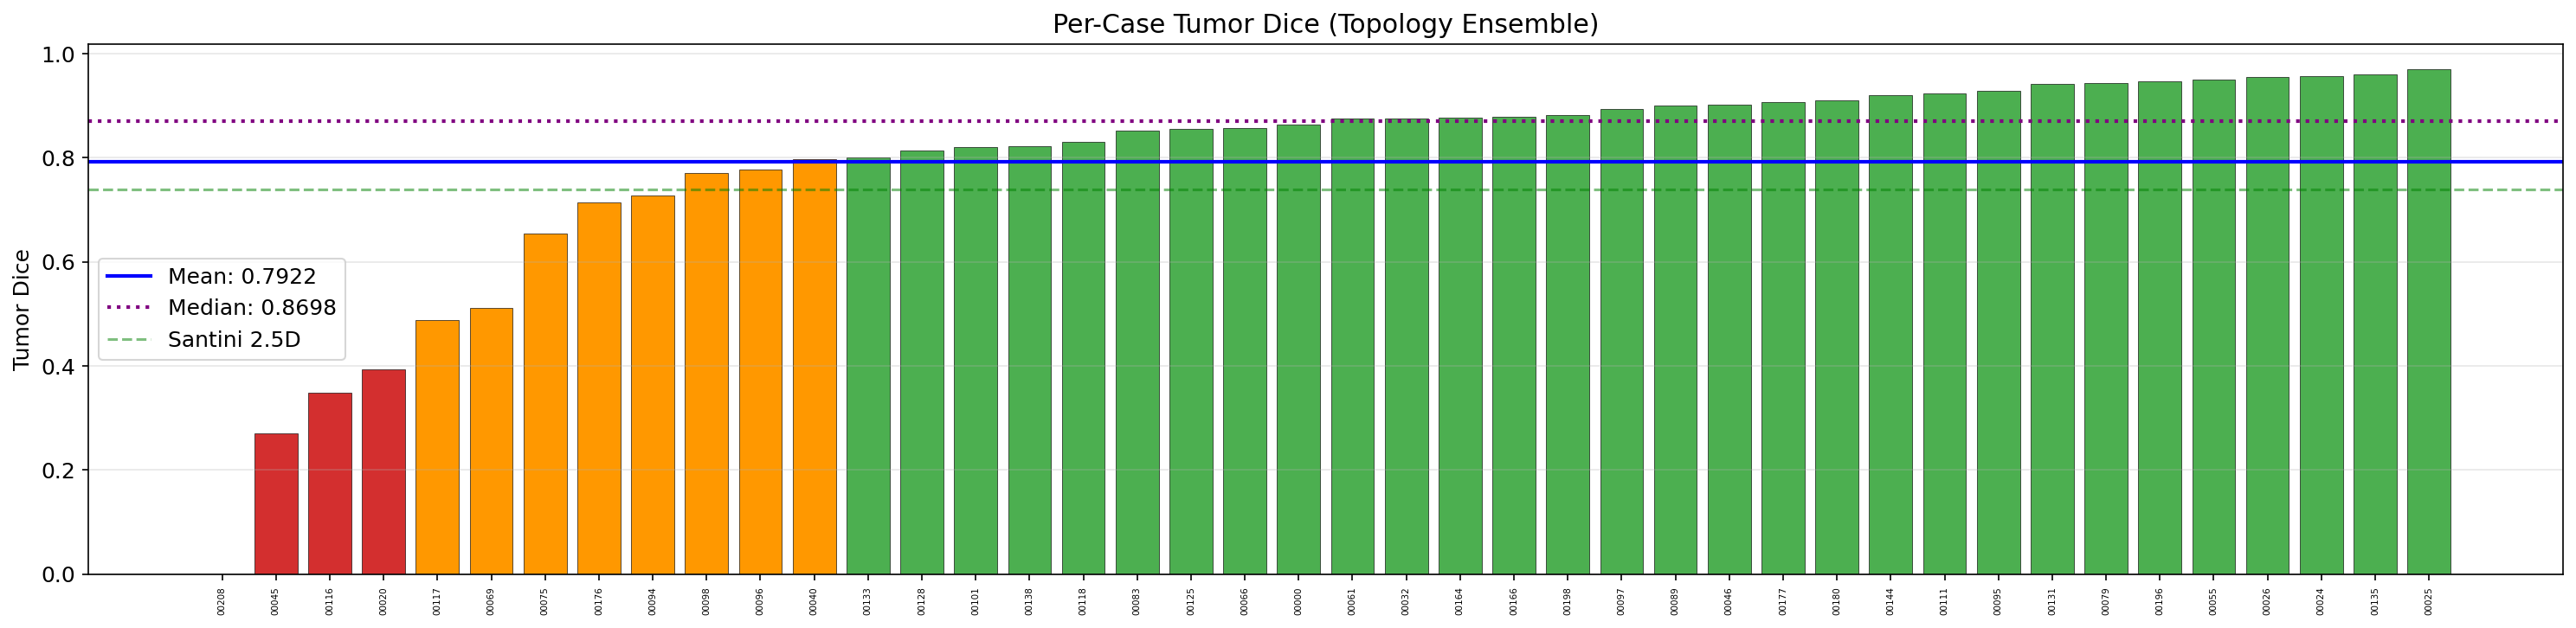

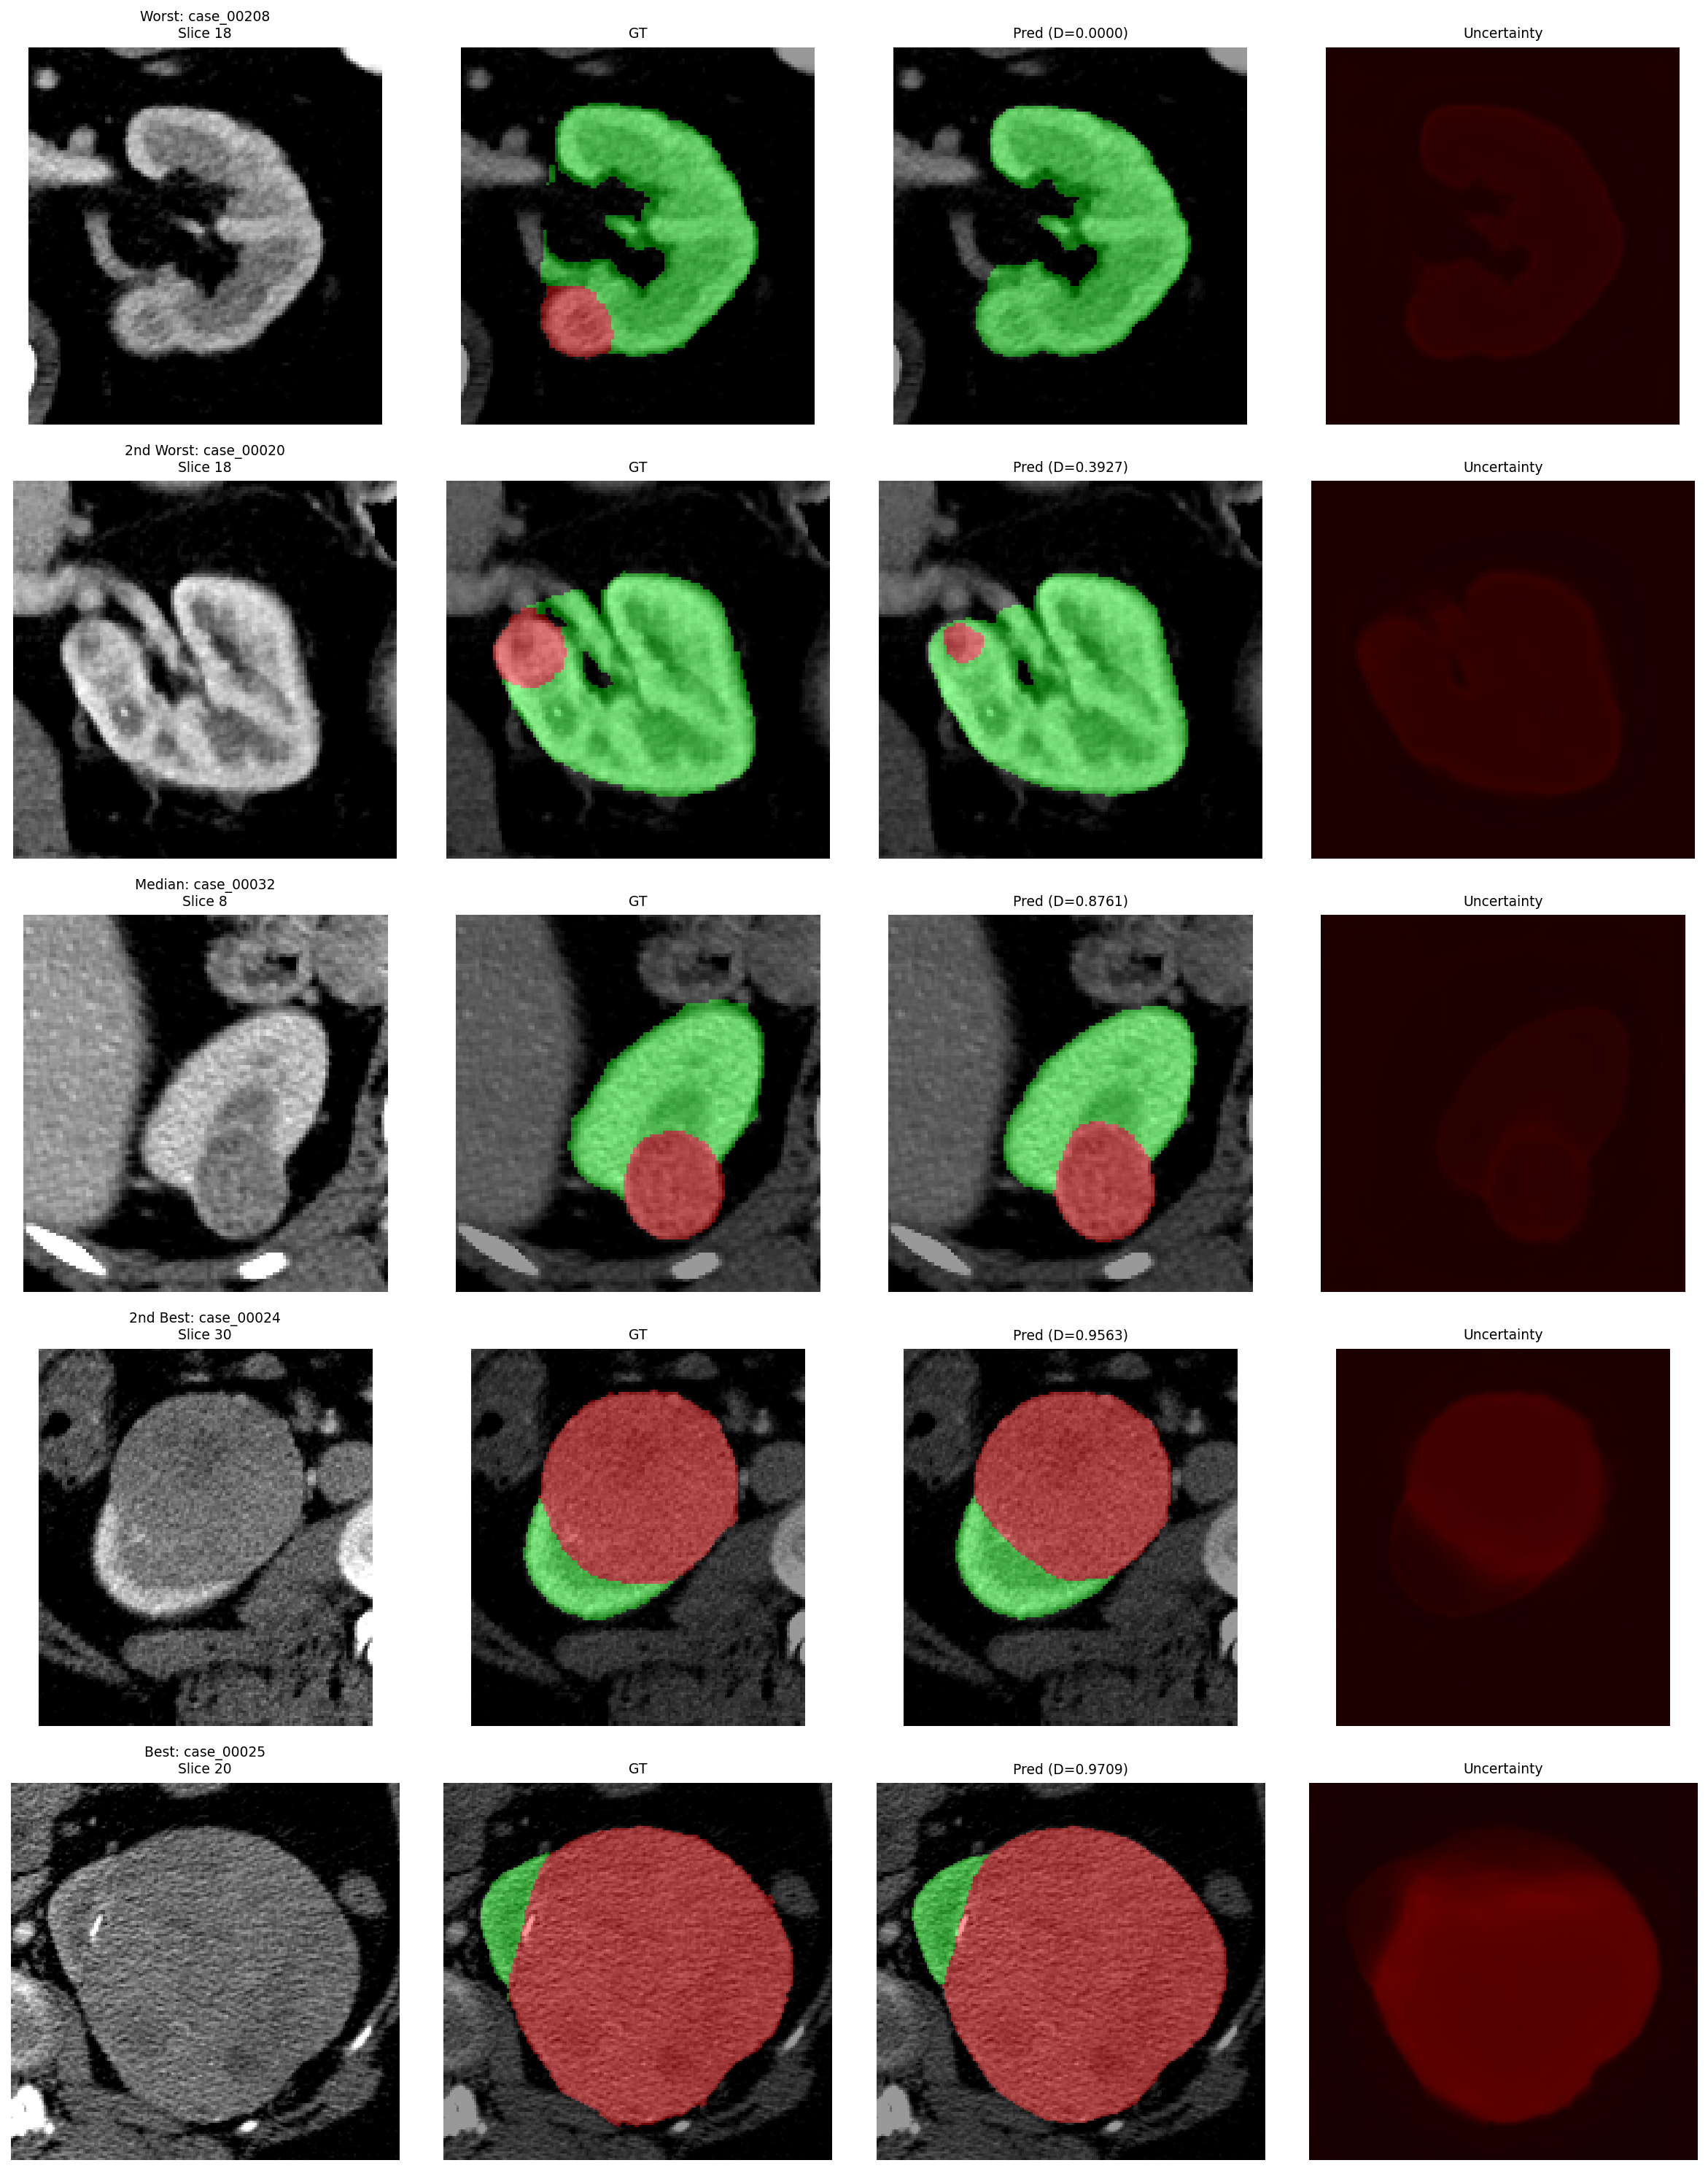

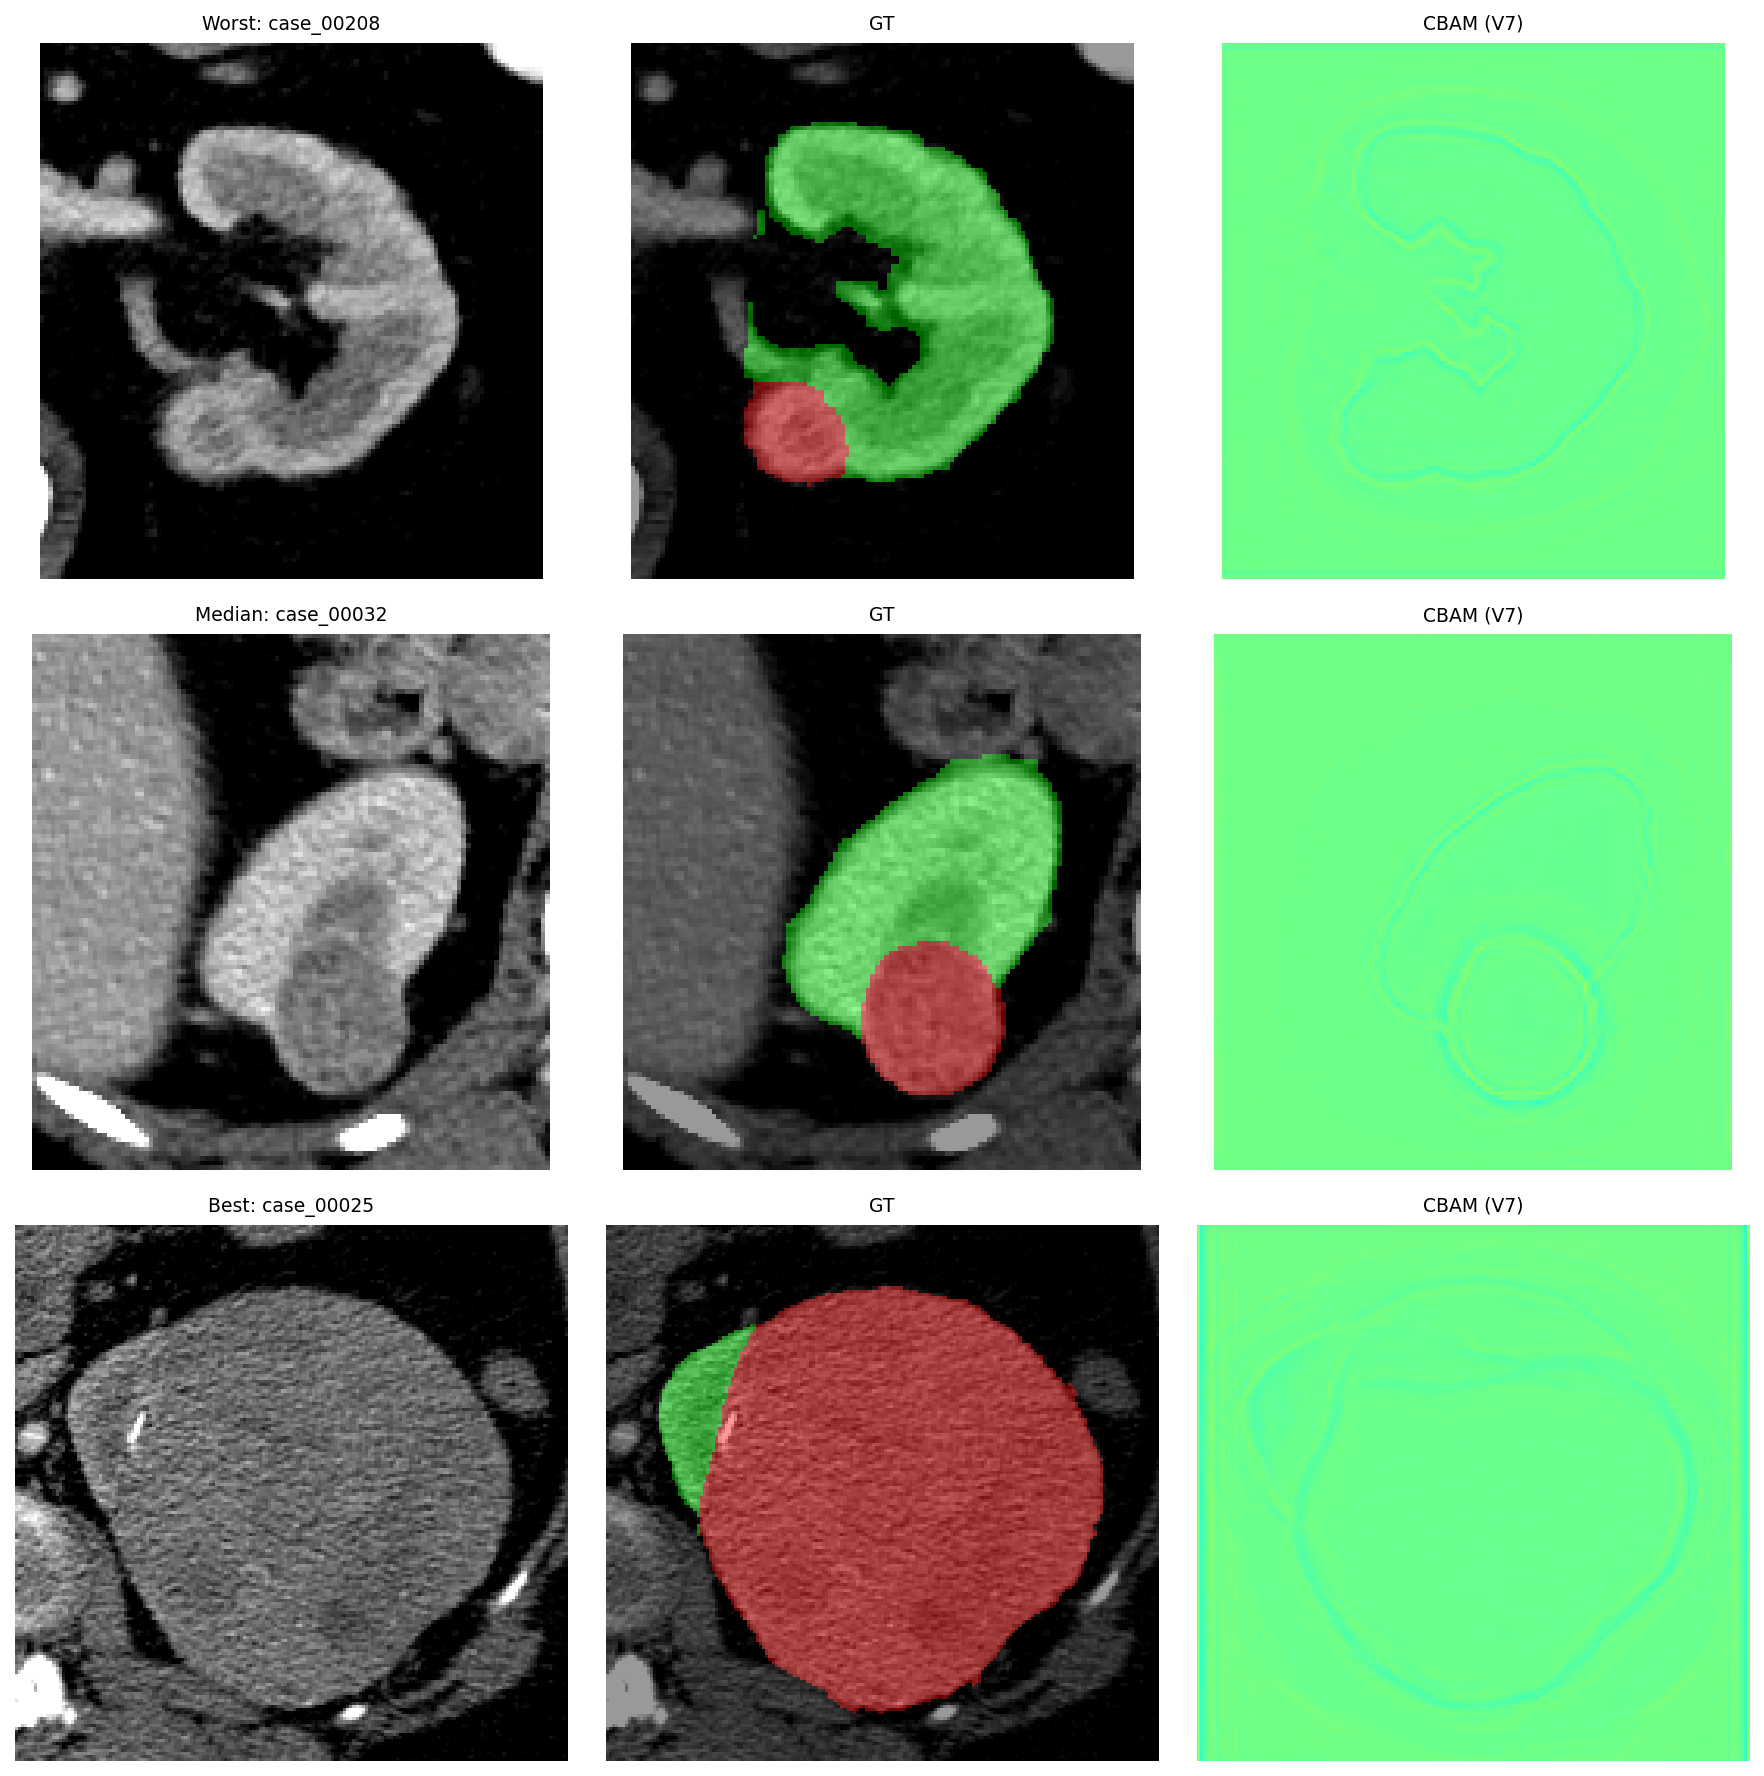

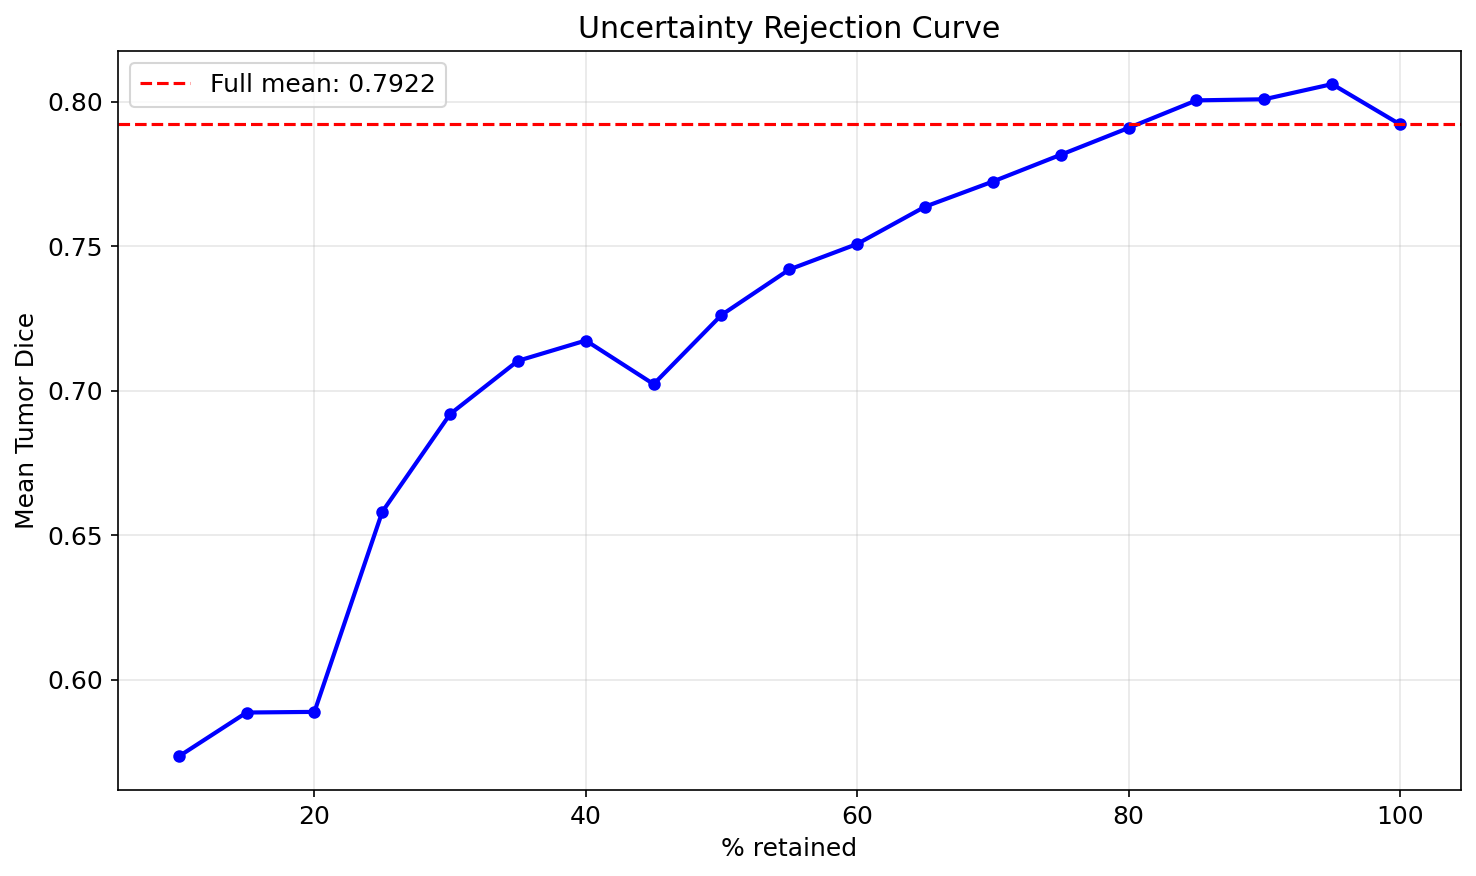

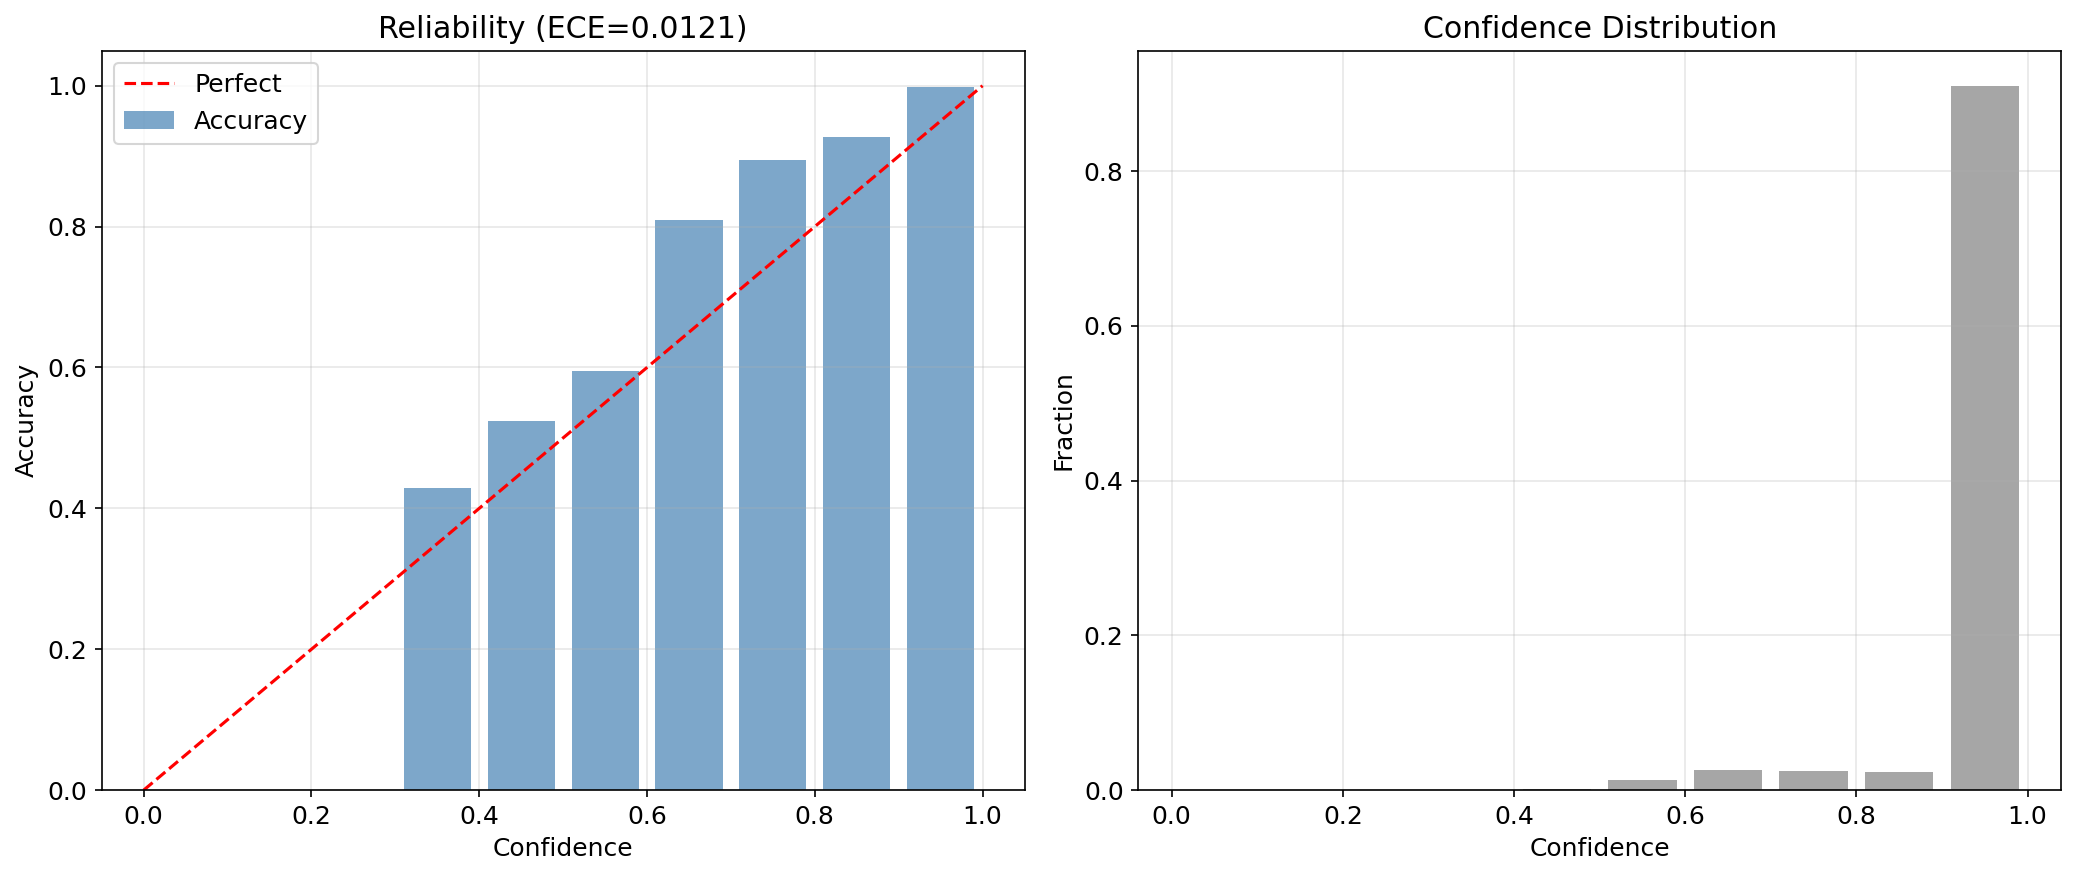

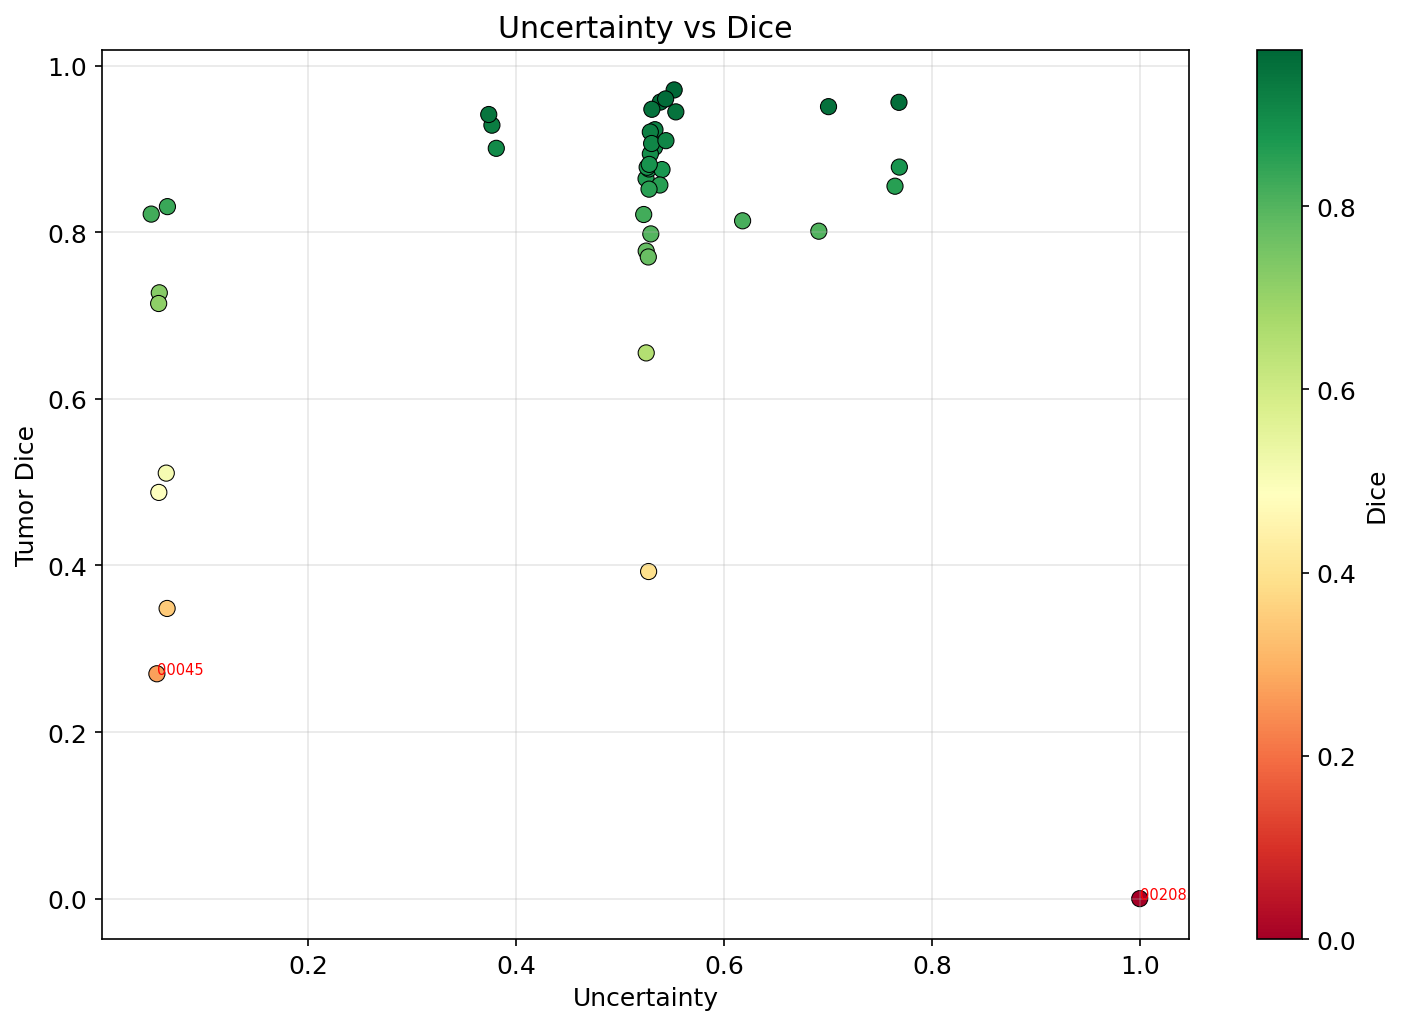

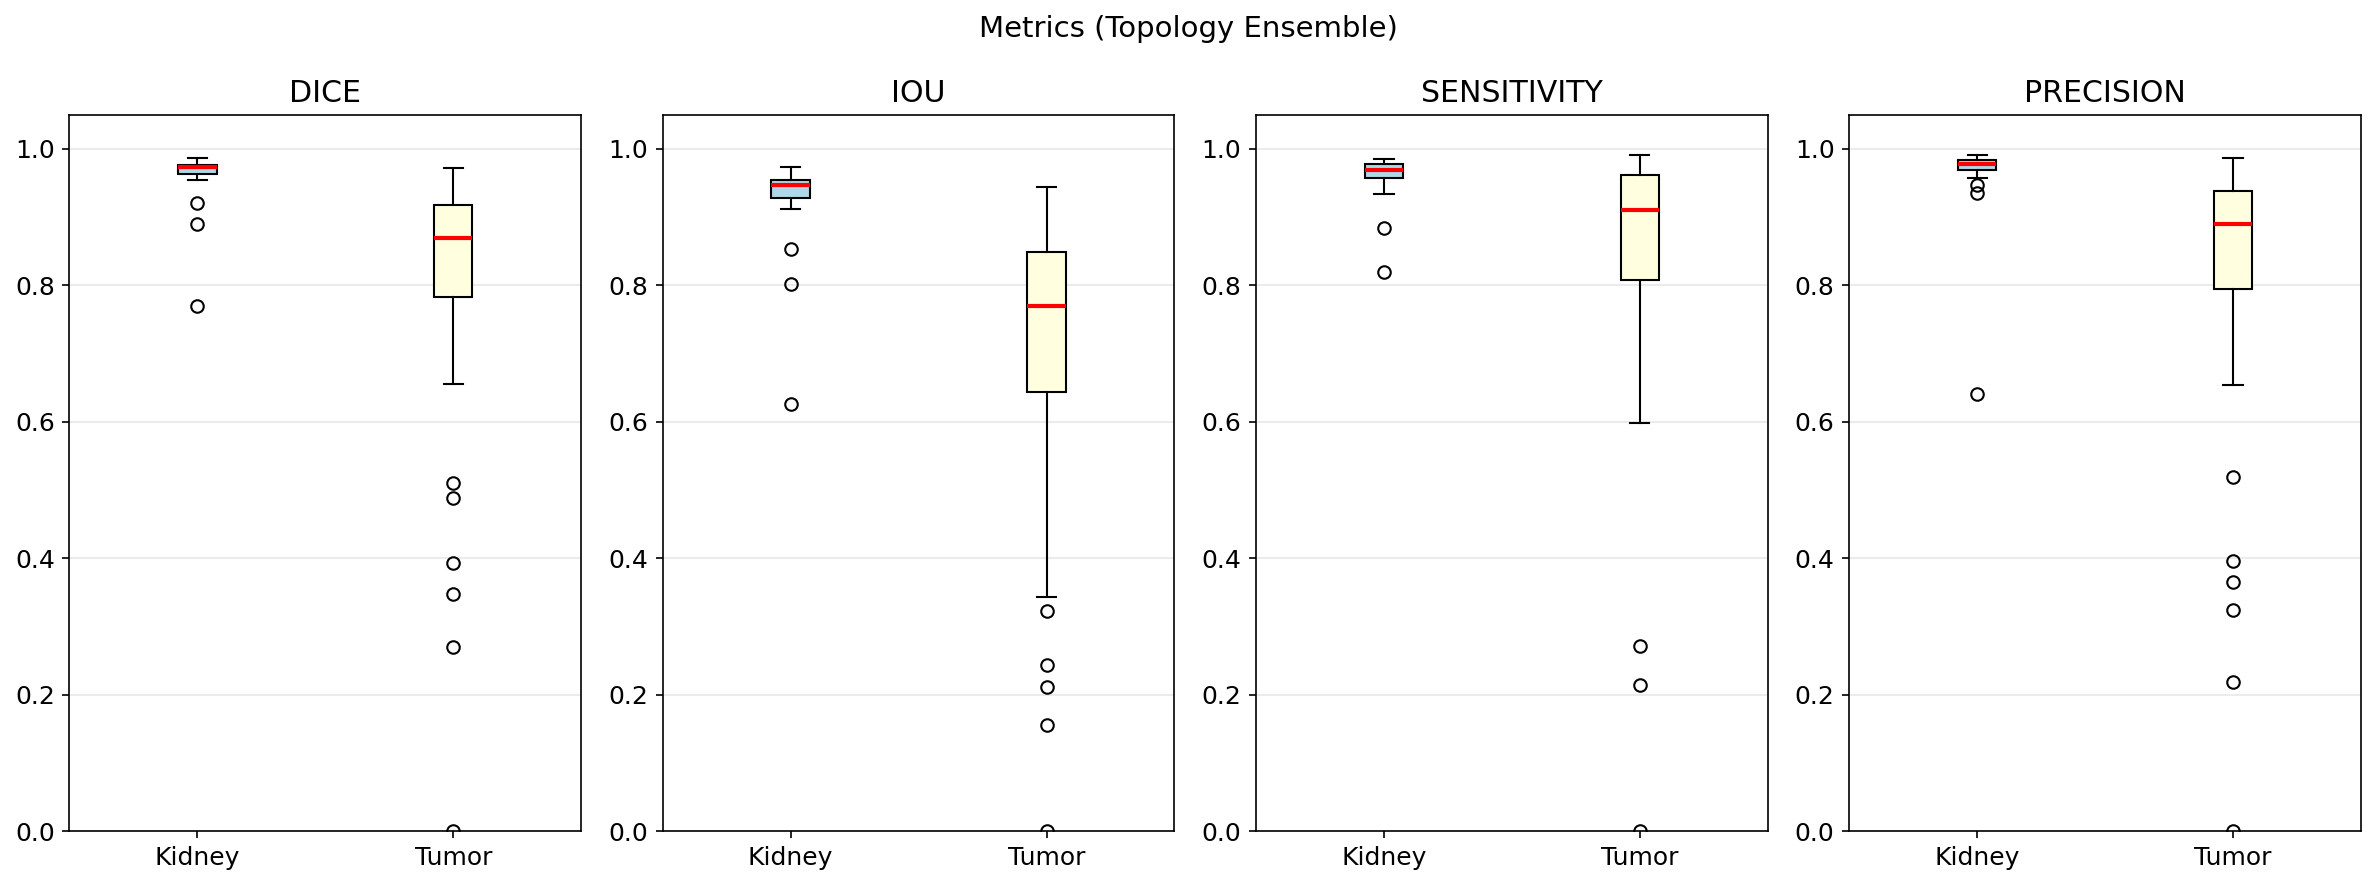

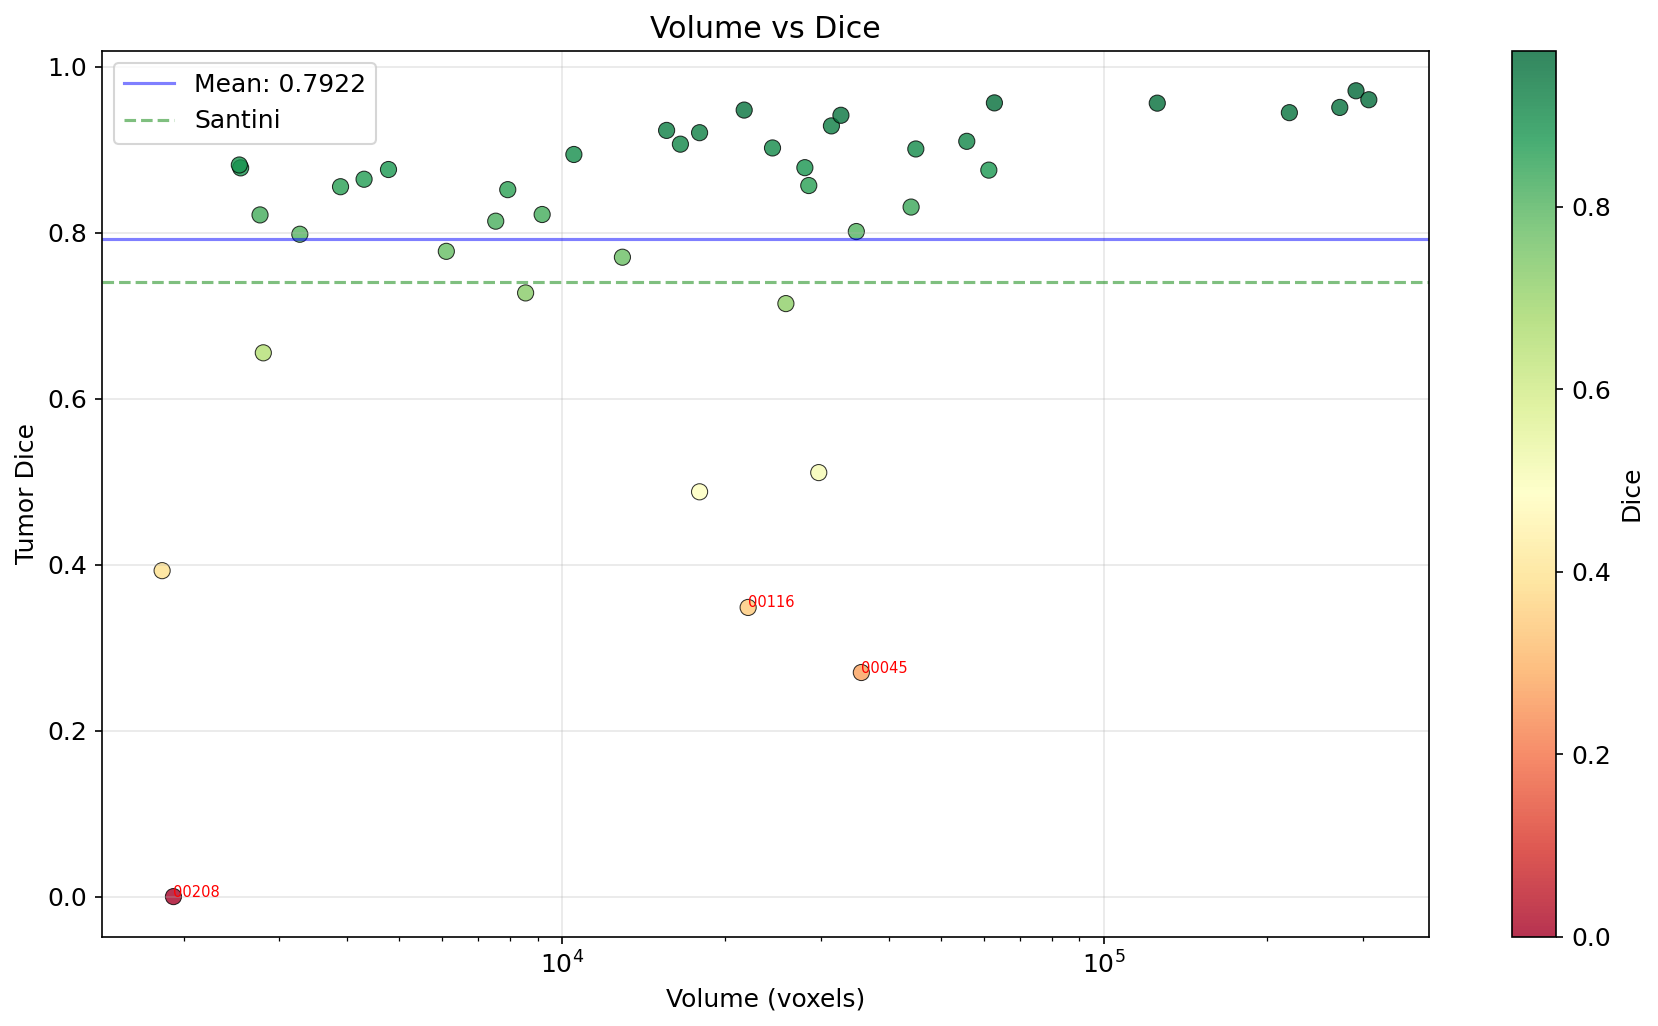

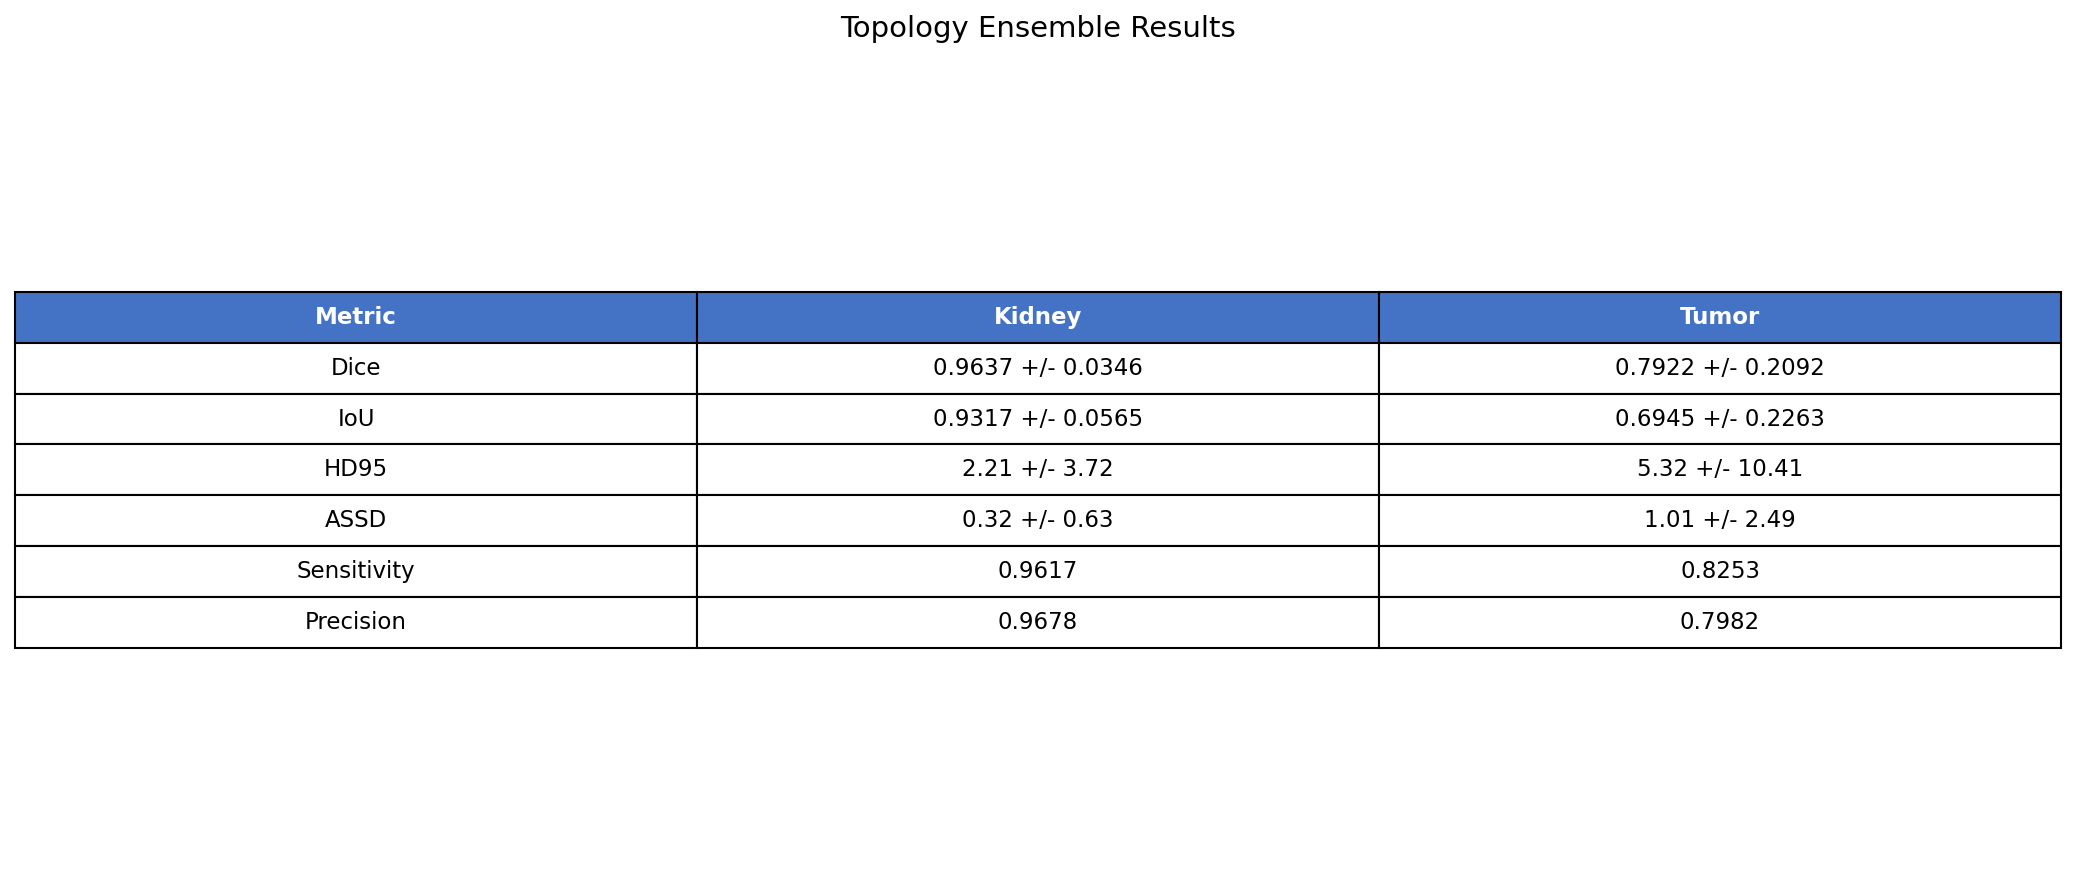

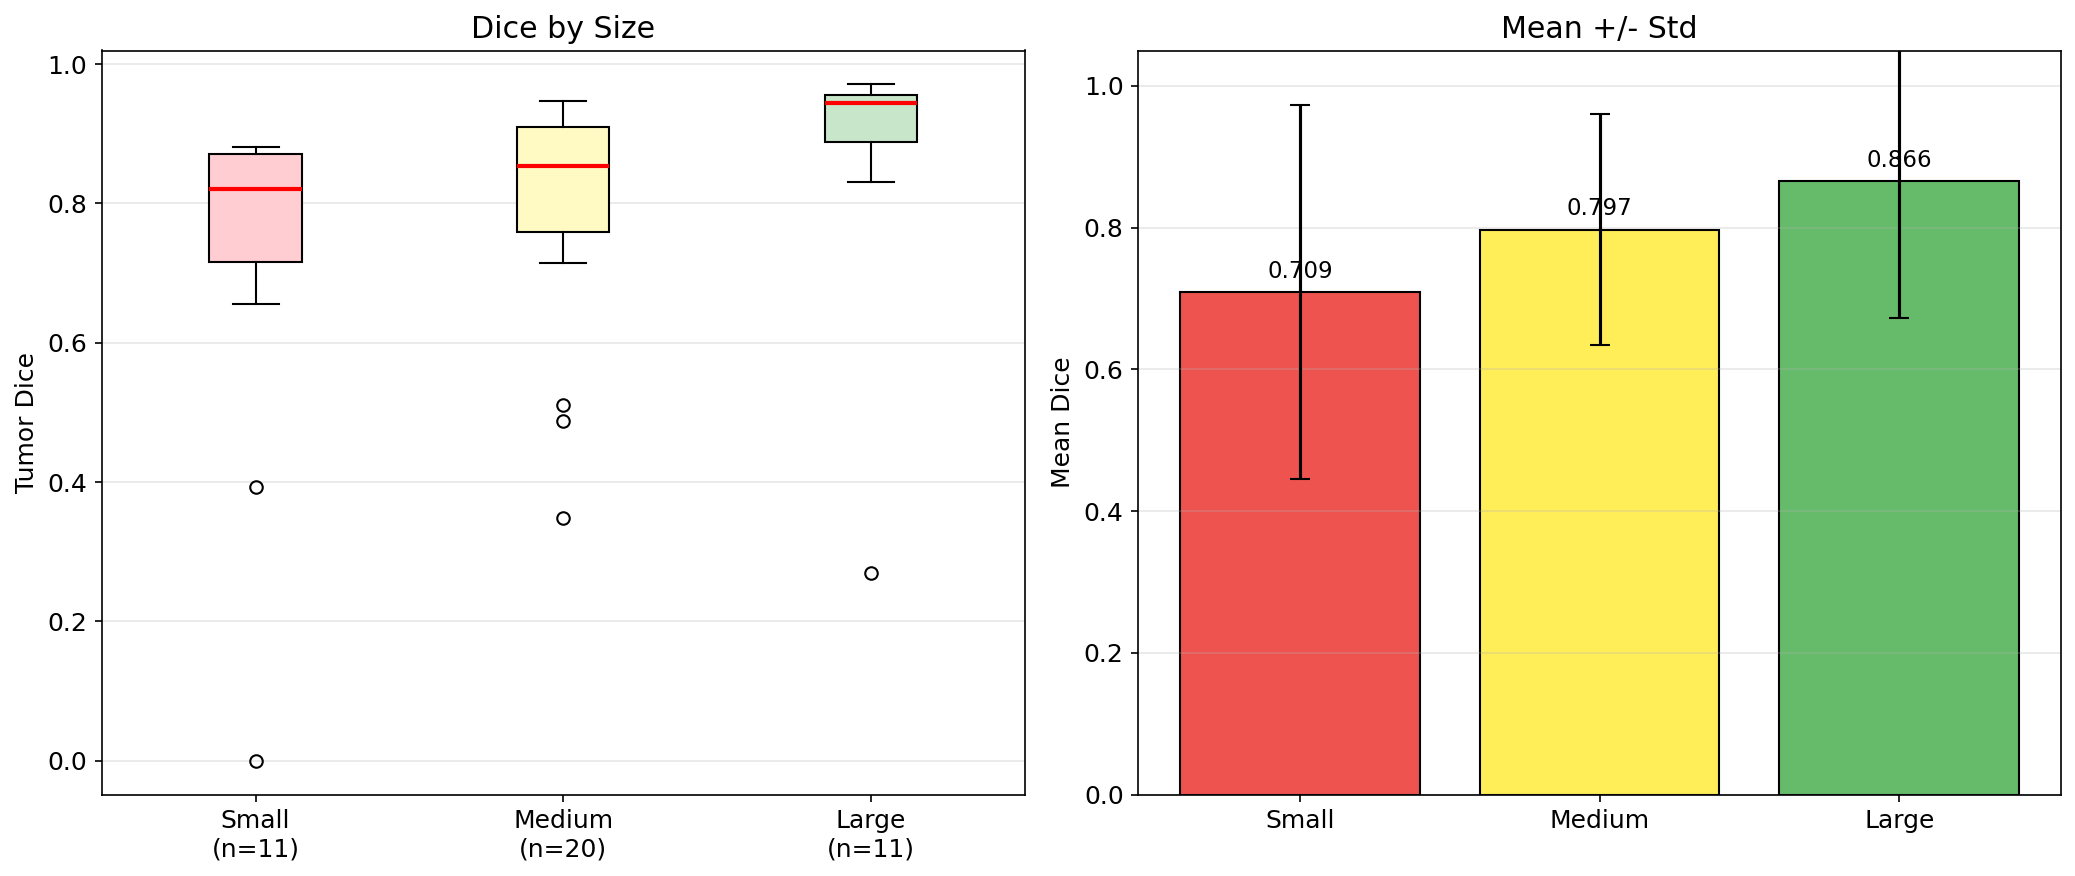

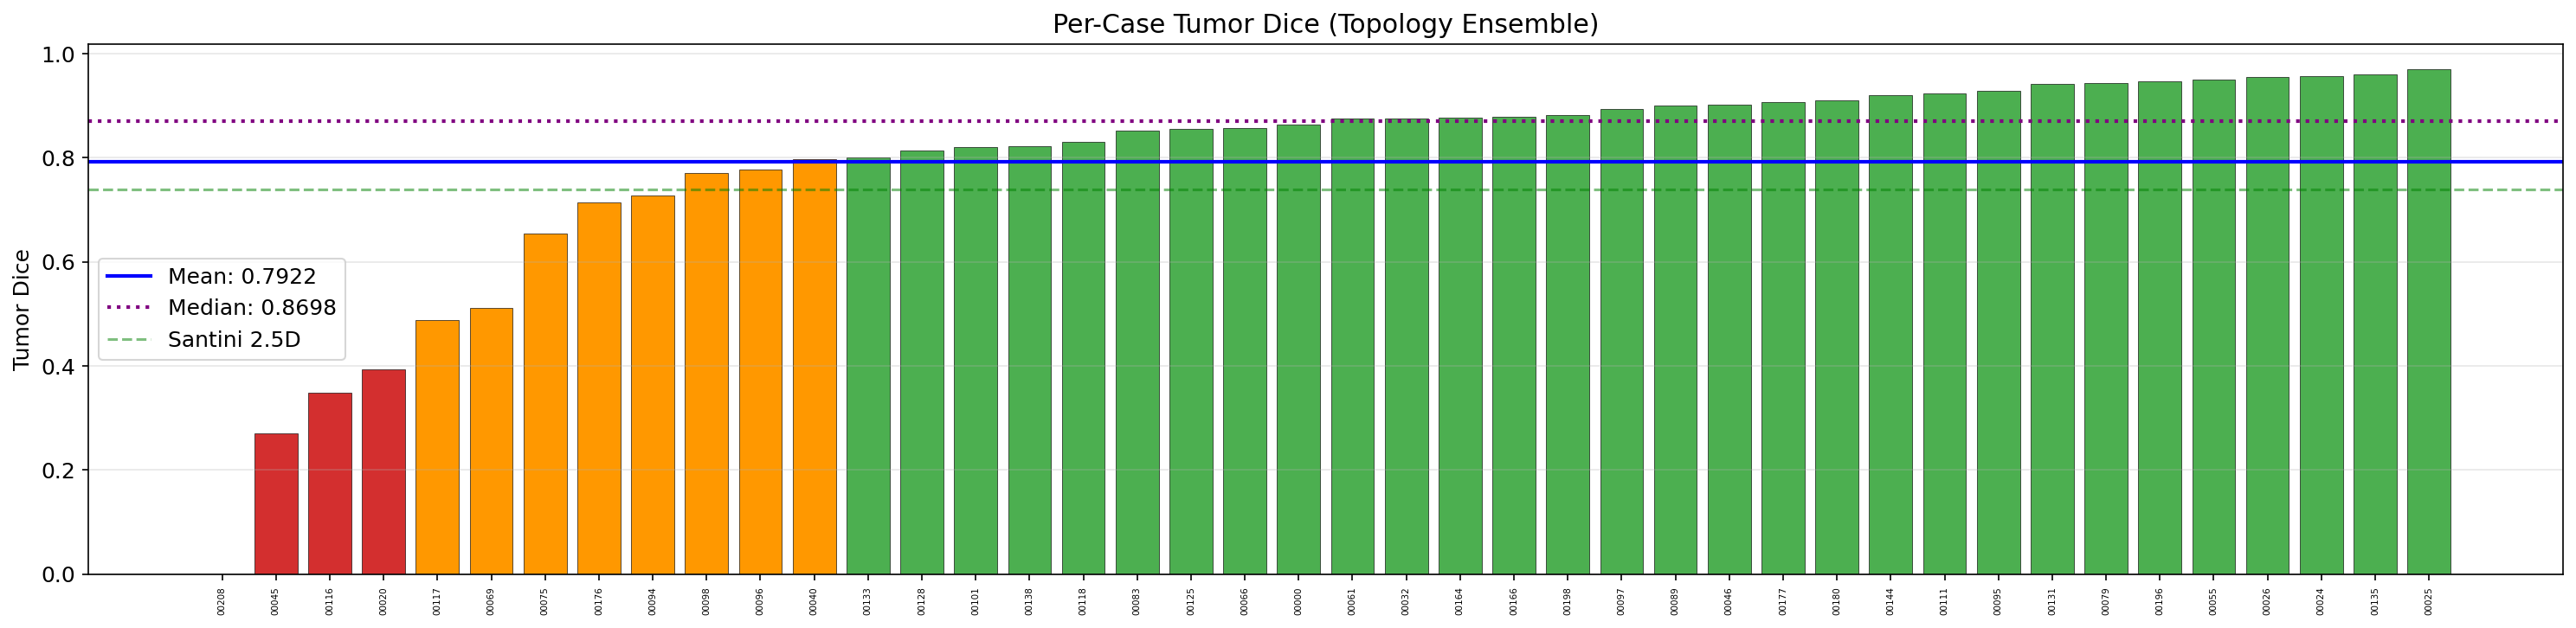

fig01


In [22]:
# Fig1
sorted_r=sorted(all_results,key=lambda r:r['tumor']['dice'])
names=[r['case_name'].replace('case_','') for r in sorted_r]
scores=[r['tumor']['dice'] for r in sorted_r]
colors=['#d32f2f' if s<0.4 else ('#ff9800' if s<0.8 else '#4caf50') for s in scores]
fig,ax=plt.subplots(figsize=(20,5))
ax.bar(range(len(names)),scores,color=colors,edgecolor='black',linewidth=0.3)
ax.axhline(np.mean(scores),color='blue',ls='-',lw=2,label=f'Mean: {np.mean(scores):.4f}')
ax.axhline(np.median(scores),color='purple',ls=':',lw=2,label=f'Median: {np.median(scores):.4f}')
ax.axhline(0.740,color='green',ls='--',alpha=0.5,label='Santini 2.5D')
ax.set_xticks(range(len(names))); ax.set_xticklabels(names,rotation=90,fontsize=5)
ax.set_ylabel('Tumor Dice'); ax.set_title('Per-Case Tumor Dice (Topology Ensemble)')
ax.legend(); ax.grid(axis='y',alpha=0.3)
plt.tight_layout(); plt.savefig(FIG_DIR/'fig01_tumor_dice_bar.png'); plt.show()
print('fig01')

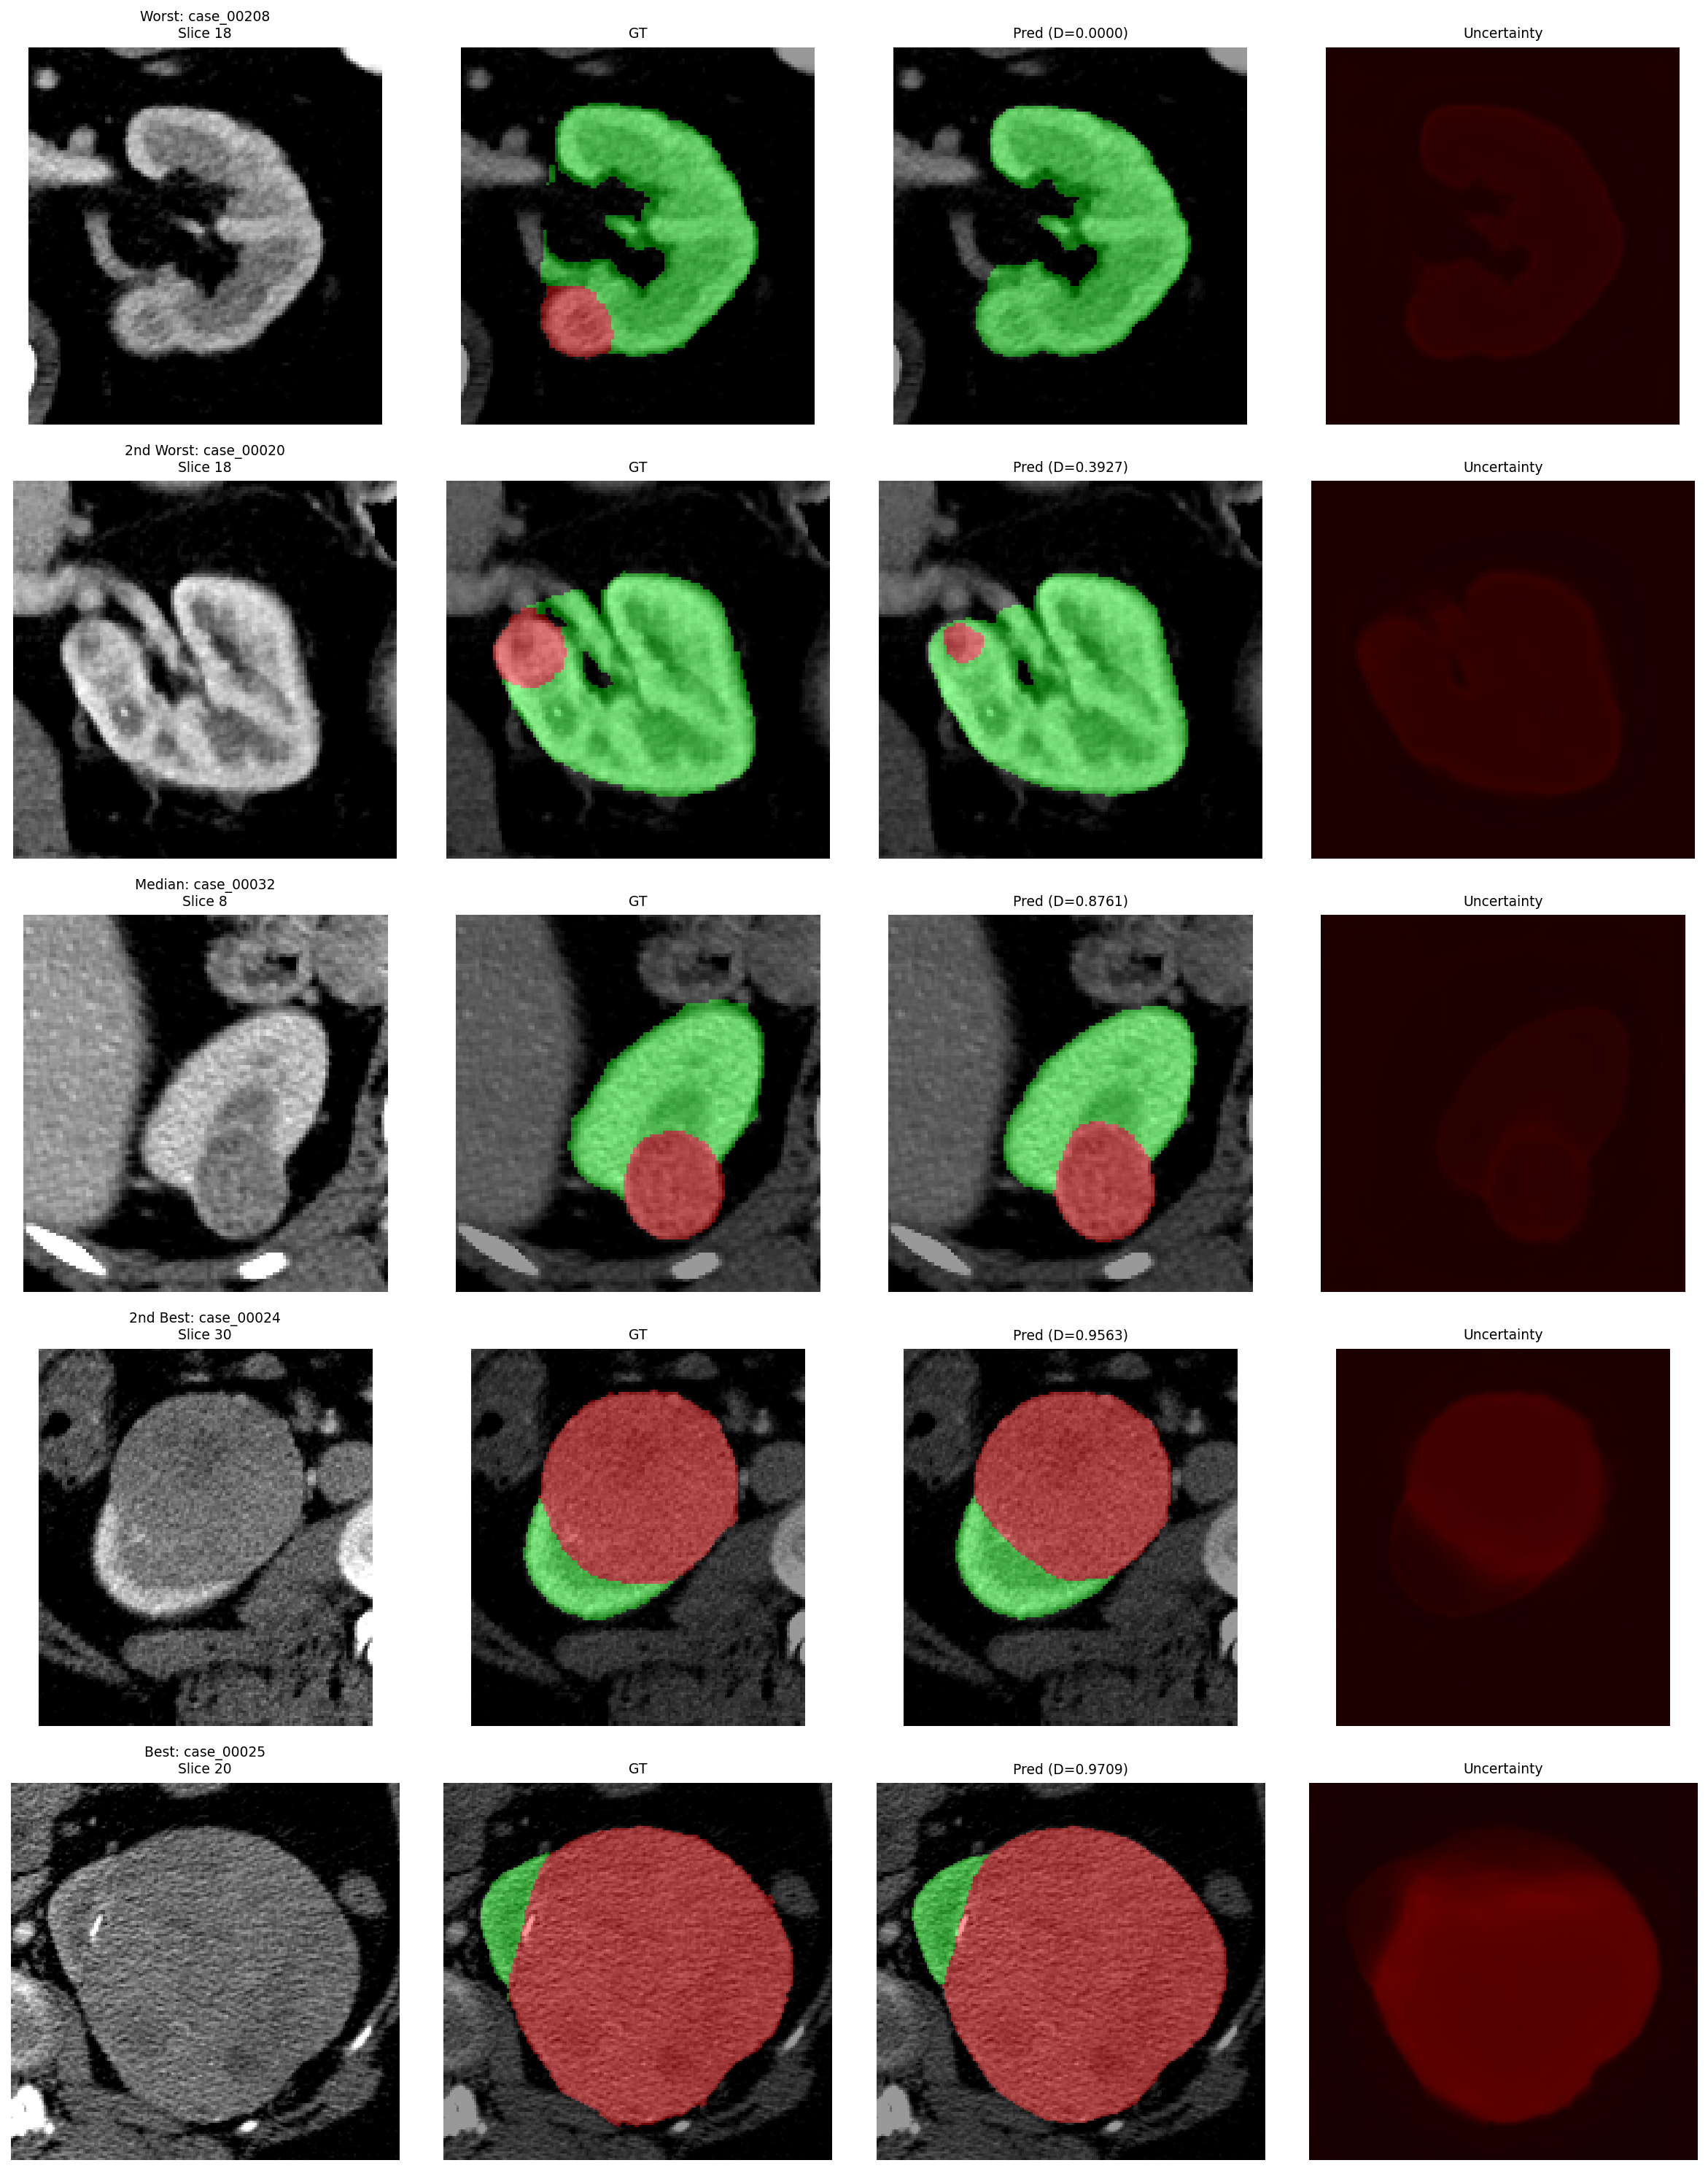

fig02


In [23]:
# Fig2
sv=sorted(viz_data.items(),key=lambda x:x[1]['td'])
if len(sv)>=5:
  picks=[sv[0],sv[1],sv[len(sv)//2],sv[-2],sv[-1]]; lbls=['Worst','2nd Worst','Median','2nd Best','Best']
  fig,axes=plt.subplots(5,4,figsize=(16,20))
  for row,((rn,vd),lbl) in enumerate(zip(picks,lbls)):
    D=vd['img'].shape[0]; tps=[(vd['gt'][s]==2).sum() for s in range(D)]; bs=np.argmax(tps) if max(tps)>0 else D//2
    axes[row,0].imshow(vd['img'][bs],cmap='gray'); axes[row,0].set_title(f'{lbl}: {vd["case"]}\nSlice {bs}',fontsize=9); axes[row,0].axis('off')
    go=np.zeros((*vd['gt'][bs].shape,3)); go[vd['gt'][bs]==1]=[0,1,0]; go[vd['gt'][bs]==2]=[1,0,0]
    axes[row,1].imshow(vd['img'][bs],cmap='gray'); axes[row,1].imshow(go,alpha=0.4); axes[row,1].set_title('GT',fontsize=9); axes[row,1].axis('off')
    po=np.zeros((*vd['pred'][bs].shape,3)); po[vd['pred'][bs]==1]=[0,1,0]; po[vd['pred'][bs]==2]=[1,0,0]
    axes[row,2].imshow(vd['img'][bs],cmap='gray'); axes[row,2].imshow(po,alpha=0.4); axes[row,2].set_title(f'Pred (D={vd["td"]:.4f})',fontsize=9); axes[row,2].axis('off')
    axes[row,3].imshow(vd['unc'][bs],cmap='hot',vmin=0,vmax=1); axes[row,3].set_title('Uncertainty',fontsize=9); axes[row,3].axis('off')
  plt.tight_layout(); plt.savefig(FIG_DIR/'fig02_best_avg_worst.png'); plt.show()
  print('fig02')

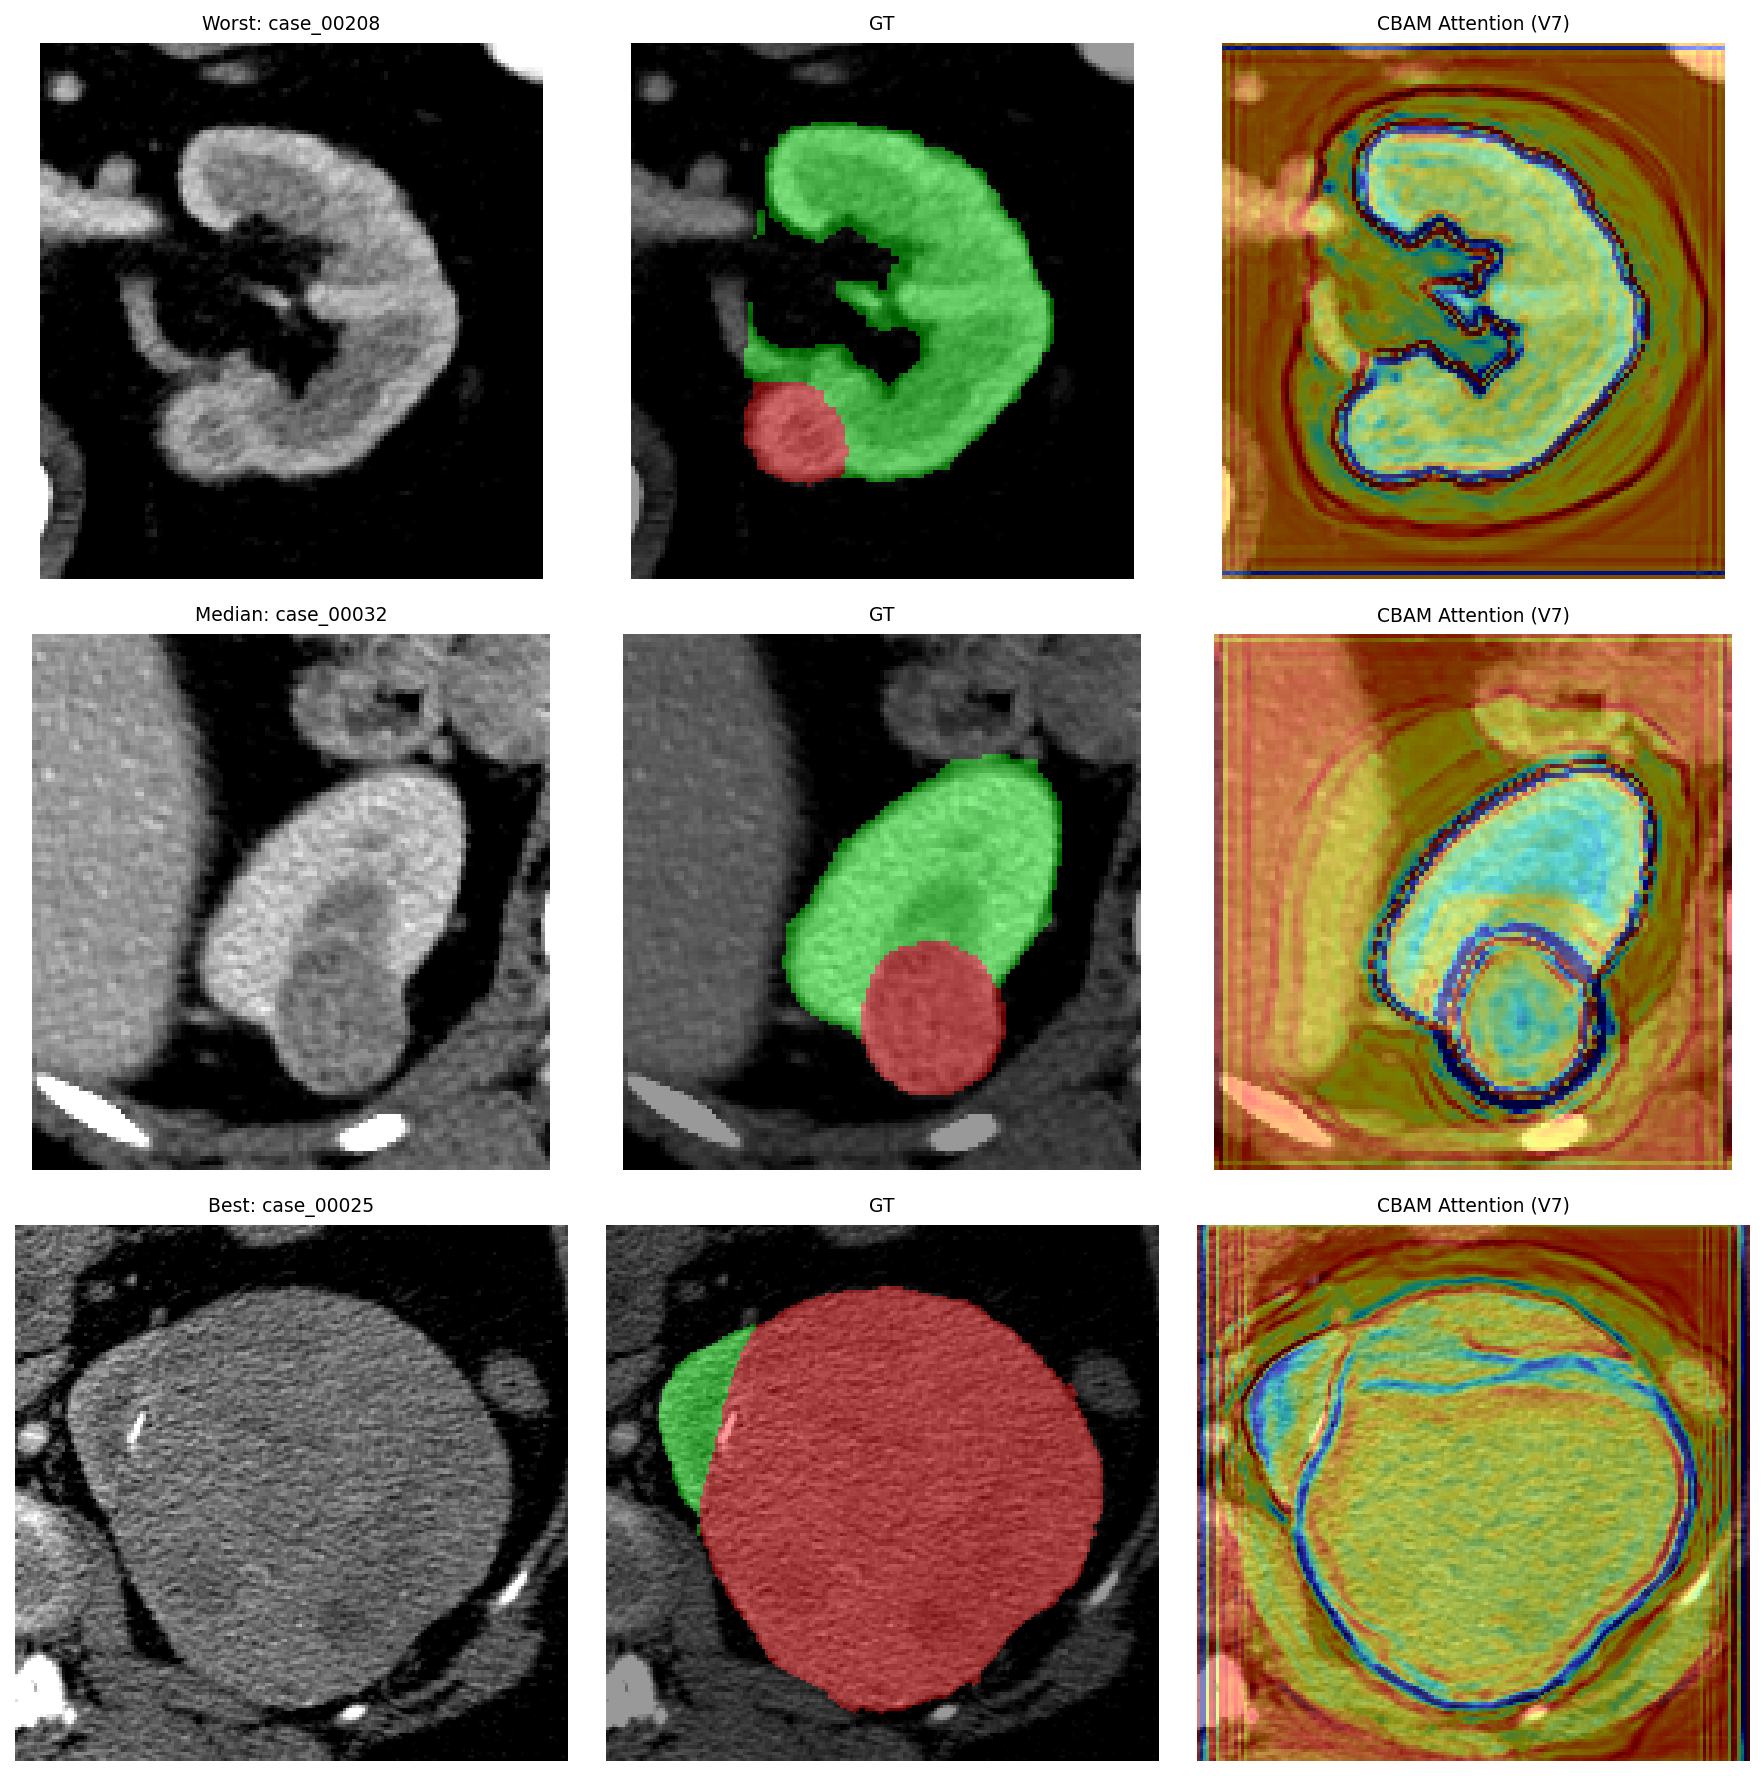

In [36]:
# ======== Figure 3: CBAM Attention Maps (FIXED: normalized + overlaid on CT) ========
if len(viz_data) >= 3:
    picks = sorted(viz_data.items(), key=lambda x: x[1]['td'])
    picks = [picks[0], picks[len(picks)//2], picks[-1]]
    fig, axes = plt.subplots(3, 3, figsize=(12, 12))
    for row, ((rn, vd), lbl) in enumerate(zip(picks, ['Worst', 'Median', 'Best'])):
        D = vd['img'].shape[0]
        tps = [(vd['gt'][s] == 2).sum() for s in range(D)]
        bs = np.argmax(tps) if max(tps) > 0 else D // 2
        
        # Column 1: CT
        axes[row, 0].imshow(vd['img'][bs], cmap='gray')
        axes[row, 0].set_title(f"{lbl}: {vd['case']}", fontsize=9)
        axes[row, 0].axis('off')
        
        # Column 2: GT overlay
        gt_ov = np.zeros((*vd['gt'][bs].shape, 3))
        gt_ov[vd['gt'][bs] == 1] = [0, 1, 0]
        gt_ov[vd['gt'][bs] == 2] = [1, 0, 0]
        axes[row, 1].imshow(vd['img'][bs], cmap='gray')
        axes[row, 1].imshow(gt_ov, alpha=0.4)
        axes[row, 1].set_title('GT', fontsize=9)
        axes[row, 1].axis('off')
        
        # Column 3: CBAM overlaid on CT (normalized per-image)
        cbam_slice = vd['cbam'][bs]
        # Normalize to [0,1] based on actual range for contrast
        cmin, cmax = np.percentile(cbam_slice, 2), np.percentile(cbam_slice, 98)
        if cmax - cmin > 1e-6:
            cbam_norm = np.clip((cbam_slice - cmin) / (cmax - cmin), 0, 1)
        else:
            cbam_norm = cbam_slice
        axes[row, 2].imshow(vd['img'][bs], cmap='gray')
        axes[row, 2].imshow(cbam_norm, cmap='jet', alpha=0.5, vmin=0, vmax=1)
        axes[row, 2].set_title('CBAM Attention (V7)', fontsize=9)
        axes[row, 2].axis('off')
    
    plt.tight_layout()
    plt.savefig(FIG_DIR / 'fig03_cbam_attention.png')
    plt.show()
    

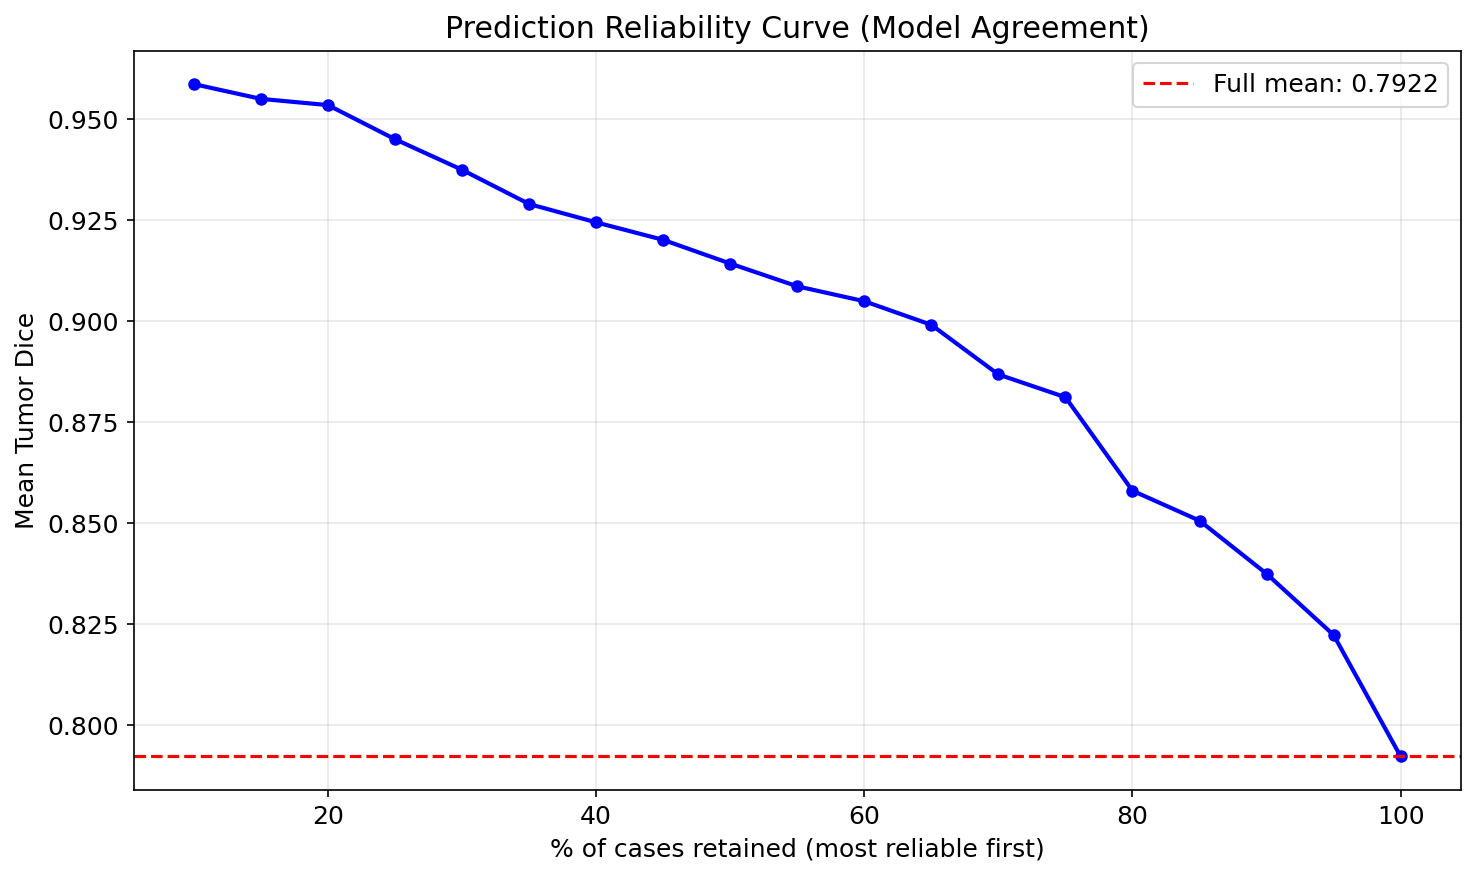

Uncertainty metric: |V5_dice - V7_dice| + 0.5*(1 - mean_dice)
Top 80% (most reliable): 0.8580
Full 100%:               0.7922
Gain from rejection:     +0.0658
Saved fig04 (model agreement)


In [38]:
# ======== Figure 4: Rejection Curve (FIXED: model disagreement as uncertainty) ========
# Load per-case results from V5 and V7
v5_path = RESULTS_DIR / 'nb07d_tta_pp.json'
v7_path = RESULTS_DIR / 'nb07f_tta_pp.json'

if v5_path.exists() and v7_path.exists():
    with open(v5_path) as f:
        v5r = {r['case']: r['tum'] for r in json.load(f)}
    with open(v7_path) as f:
        v7r = {r['case']: r['tum'] for r in json.load(f)}
    
    # Uncertainty = |V5_dice - V7_dice| — high disagreement = uncertain
    # Also: cases where BOTH models score low = truly hard
    unc_disagree = []
    tum_dices = []
    for r in all_results:
        cn = r['case_name']
        v5d = v5r.get(cn, 0)
        v7d = v7r.get(cn, 0)
        # Combine disagreement + difficulty: 
        # high disagreement OR low mean score → high uncertainty
        disagree = abs(v5d - v7d)
        mean_score = (v5d + v7d) / 2
        unc = disagree + (1 - mean_score) * 0.5  # blend: disagreement + difficulty
        unc_disagree.append(unc)
        tum_dices.append(r['tumor']['dice'])
    
    # Sort by uncertainty ascending (most certain = lowest disagreement + high scores)
    paired = sorted(zip(unc_disagree, tum_dices), key=lambda x: x[0])
    
    fractions, mean_dices = [], []
    for frac_pct in range(10, 101, 5):
        n_keep = max(1, int(len(paired) * frac_pct / 100))
        kept = paired[:n_keep]
        mean_dices.append(np.mean([d for _, d in kept]))
        fractions.append(frac_pct)
    
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(fractions, mean_dices, 'b-o', linewidth=2, markersize=5)
    ax.axhline(np.mean(tum_dices), color='red', ls='--', 
               label=f'Full mean: {np.mean(tum_dices):.4f}')
    ax.set_xlabel('% of cases retained (most reliable first)')
    ax.set_ylabel('Mean Tumor Dice')
    ax.set_title('Prediction Reliability Curve (Model Agreement)')
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIG_DIR / 'fig04_rejection_curve.png')
    plt.show()
    
    # Show the correlation
    print(f"Uncertainty metric: |V5_dice - V7_dice| + 0.5*(1 - mean_dice)")
    print(f"Top 80% (most reliable): {mean_dices[fractions.index(80)]:.4f}")
    print(f"Full 100%:               {np.mean(tum_dices):.4f}")
    print(f"Gain from rejection:     +{mean_dices[fractions.index(80)] - np.mean(tum_dices):.4f}")
    print("Saved fig04 (model agreement)")
else:
    print("V5/V7 per-case results not found — run NB07d/NB07f E2E first")

Computing ECE...


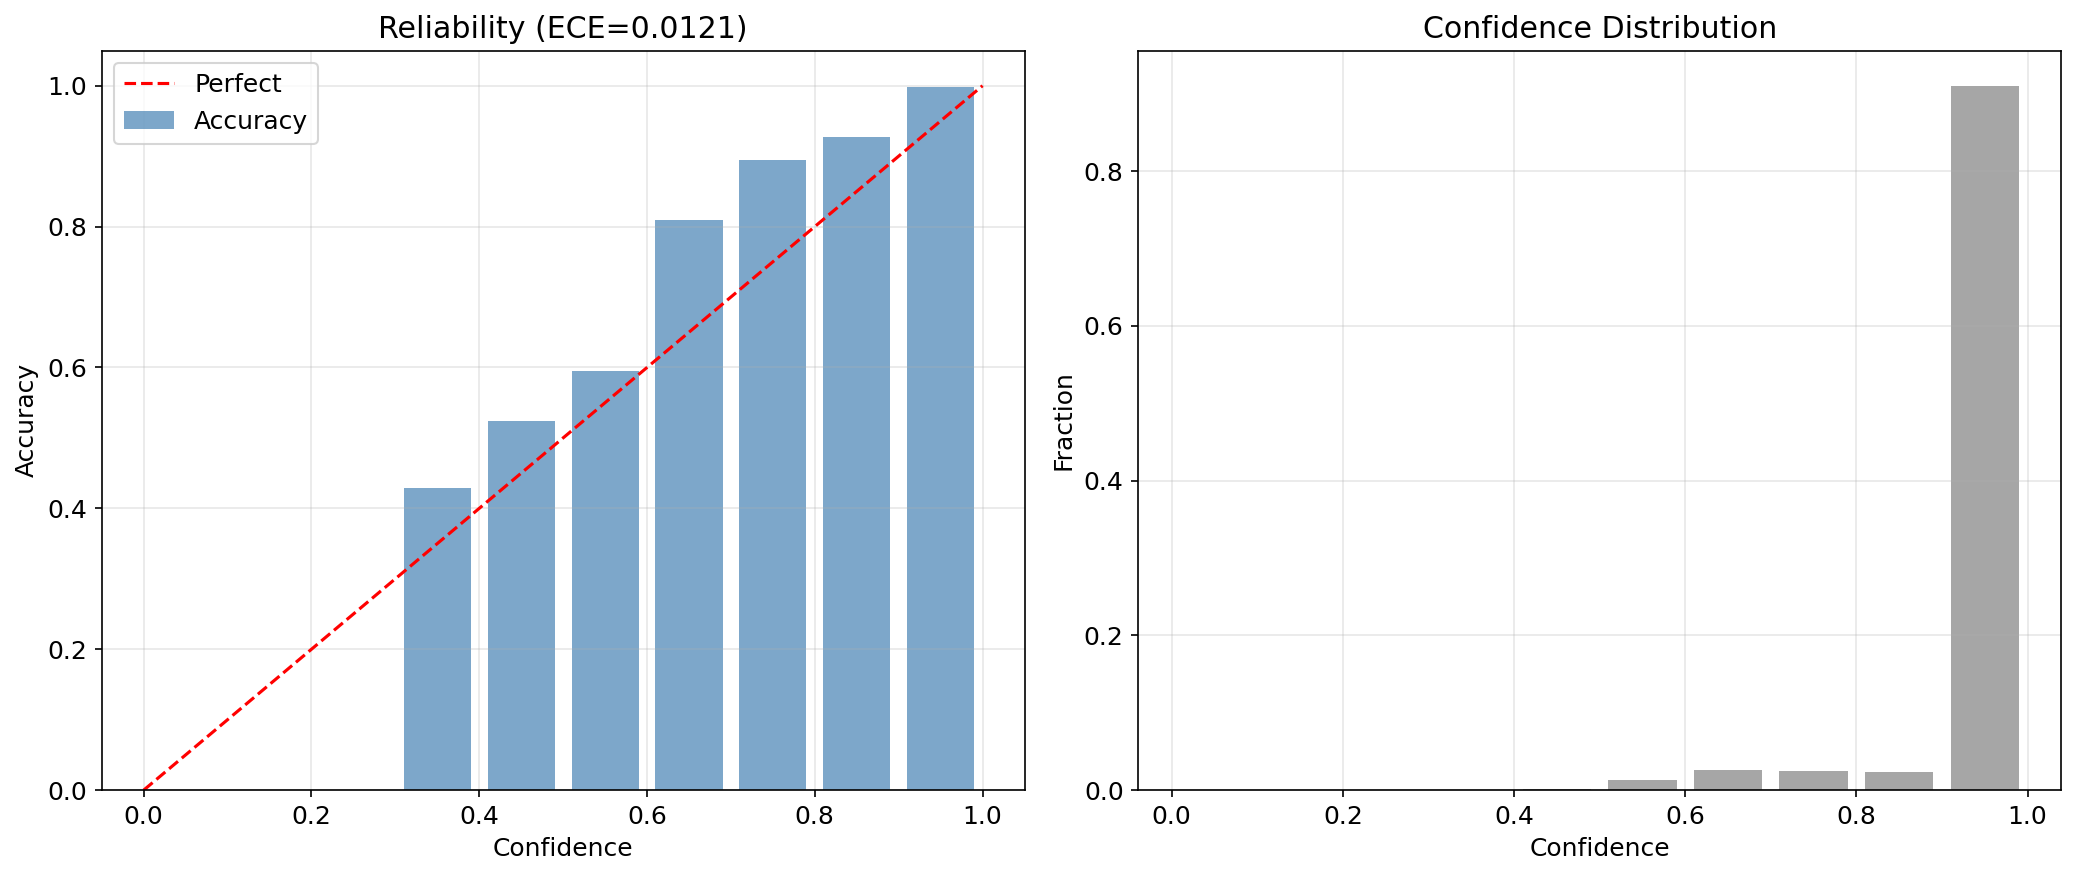

ECE: 0.0121


In [26]:
# Fig5
print('Computing ECE...')
nb_=10; bb=np.linspace(0,1,nb_+1); bc=np.zeros(nb_); bf=np.zeros(nb_); bn=np.zeros(nb_)
for rn,vd in viz_data.items():
  gt=vd['gt']; prob=vd['prob']; D=gt.shape[0]
  for s in range(0,D,max(1,D//5)):
    ps=prob[:,s]; cm=ps.max(axis=0); pm=ps.argmax(axis=0); correct=(pm==gt[s]).astype(float)
    for b in range(nb_):
      mask=(cm>=bb[b])&(cm<bb[b+1])
      if mask.sum()>0: bc[b]+=correct[mask].sum(); bf[b]+=cm[mask].sum(); bn[b]+=mask.sum()
ba=bc/np.maximum(bn,1); bconf=bf/np.maximum(bn,1)
ece=float(np.sum(bn/max(bn.sum(),1)*np.abs(ba-bconf)))
fig,(a1,a2)=plt.subplots(1,2,figsize=(14,6)); ct=(bb[:-1]+bb[1:])/2
a1.bar(ct,ba,width=0.08,alpha=0.7,color='steelblue',label='Accuracy'); a1.plot([0,1],[0,1],'r--',label='Perfect')
a1.set_xlabel('Confidence'); a1.set_ylabel('Accuracy'); a1.set_title(f'Reliability (ECE={ece:.4f})'); a1.legend(); a1.grid(True,alpha=0.3)
a2.bar(ct,bn/max(bn.sum(),1),width=0.08,color='gray',alpha=0.7); a2.set_xlabel('Confidence'); a2.set_ylabel('Fraction'); a2.set_title('Confidence Distribution'); a2.grid(True,alpha=0.3)
plt.tight_layout(); plt.savefig(FIG_DIR/'fig05_ece.png'); plt.show()
print(f'ECE: {ece:.4f}')

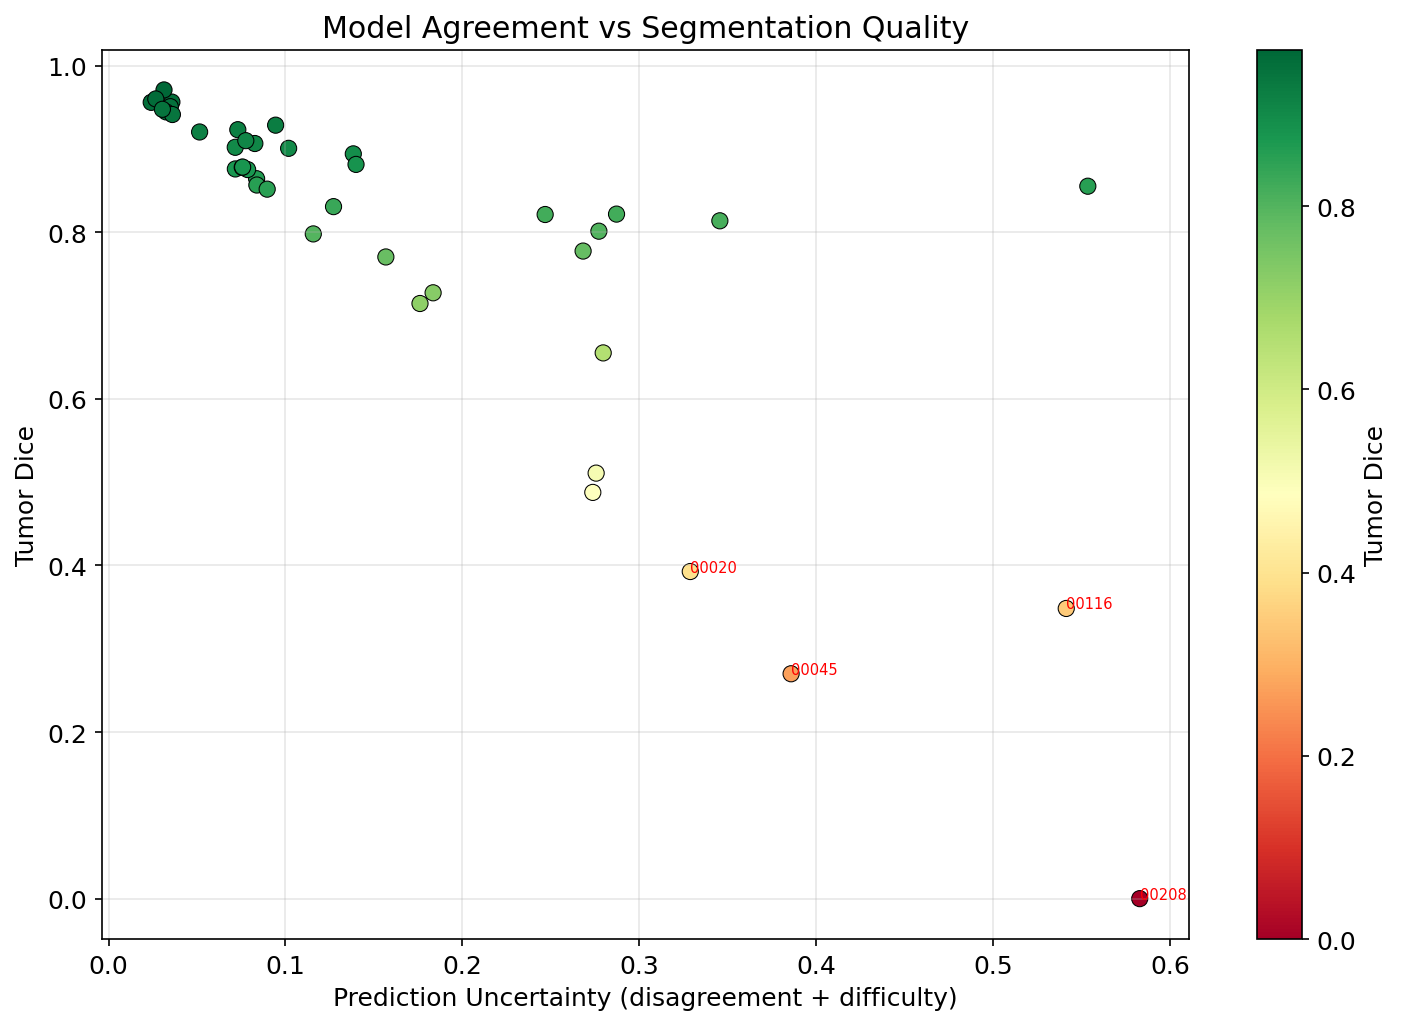

Saved fig06 (model agreement)


In [40]:
# ======== Figure 6: Model Agreement vs Dice ========
if v5_path.exists() and v7_path.exists():
    fig, ax = plt.subplots(figsize=(10, 7))
    sc = ax.scatter(unc_disagree, tum_dices, c=tum_dices, cmap='RdYlGn', 
                     s=60, edgecolors='black', linewidth=0.5)
    plt.colorbar(sc, label='Tumor Dice')
    for r, u in zip(all_results, unc_disagree):
        if r['tumor']['dice'] < 0.40:
            ax.annotate(r['case_name'].replace('case_', ''), 
                       (u, r['tumor']['dice']), fontsize=7, color='red')
    ax.set_xlabel('Prediction Uncertainty (disagreement + difficulty)')
    ax.set_ylabel('Tumor Dice')
    ax.set_title('Model Agreement vs Segmentation Quality')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIG_DIR / 'fig06_unc_vs_dice.png')
    plt.show()
    print("Saved fig06 (model agreement)")


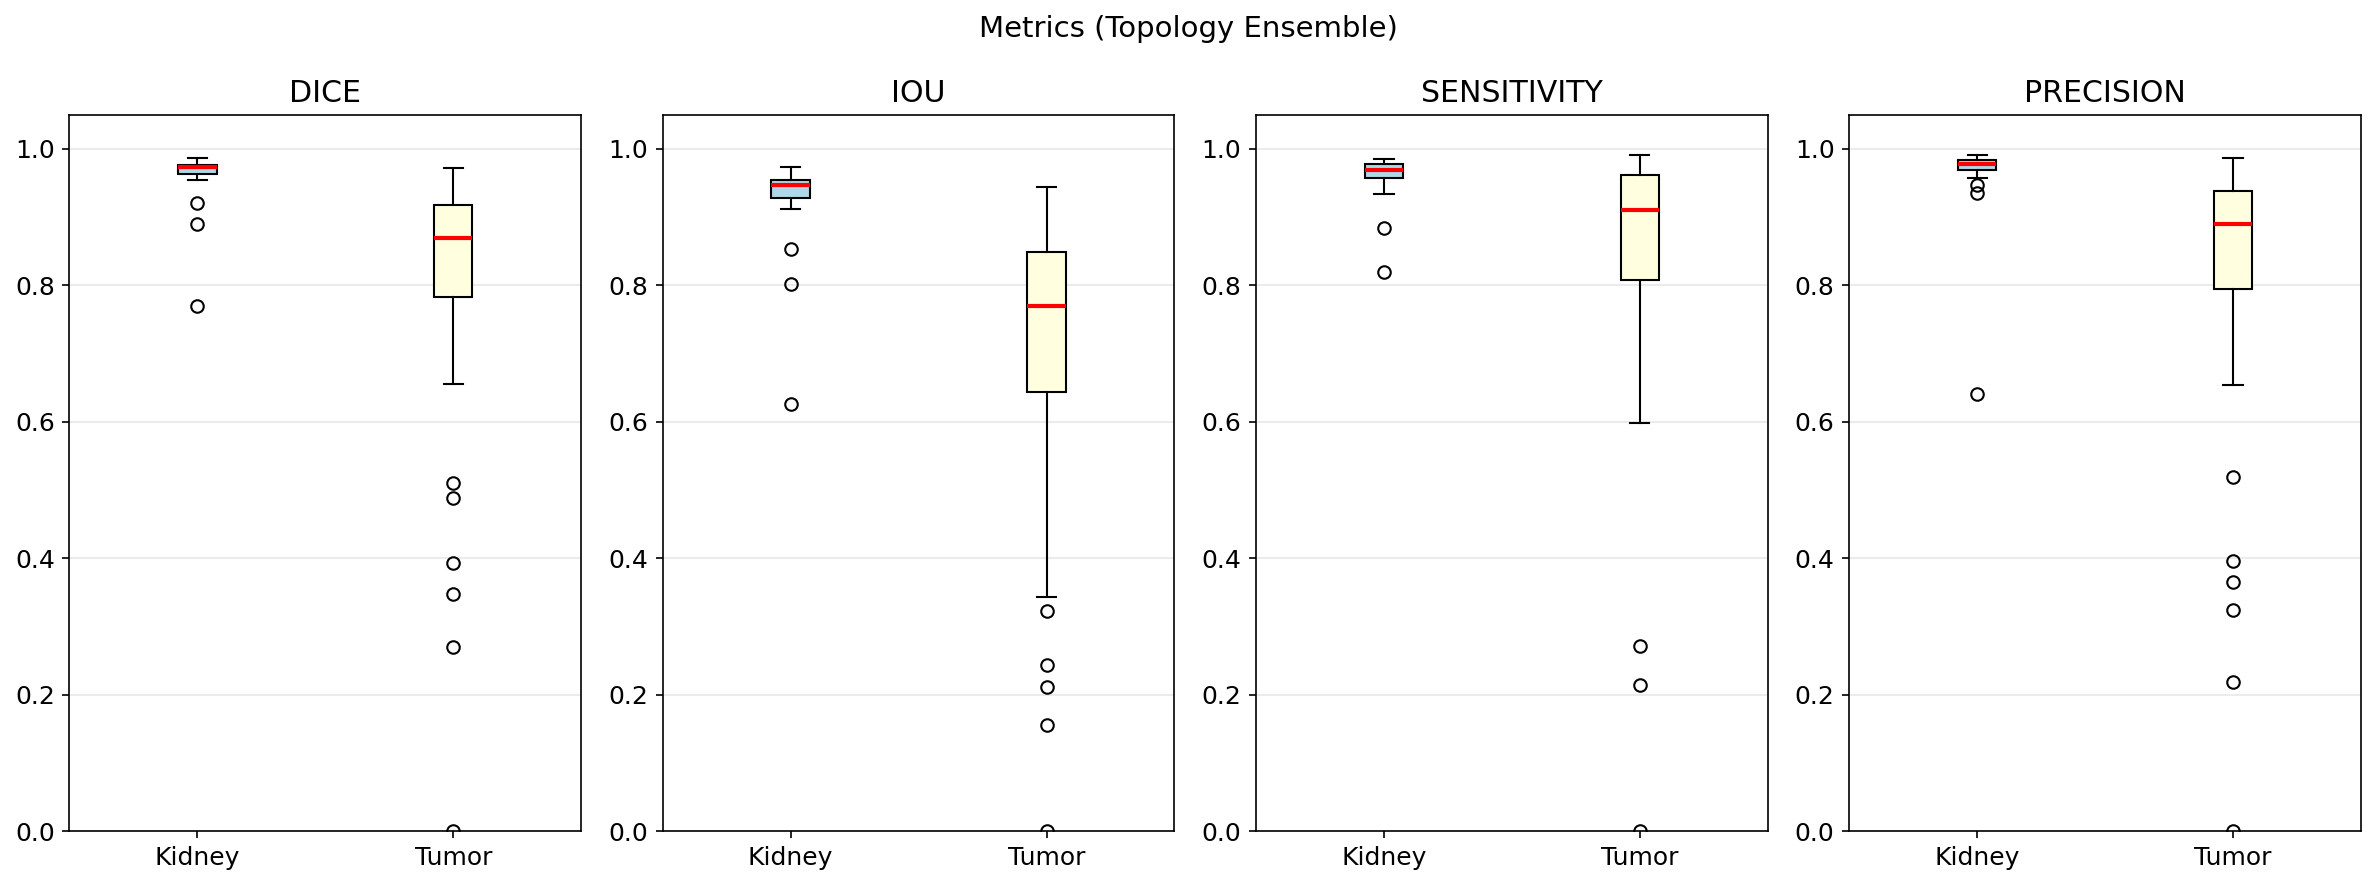

fig07


In [28]:
# Fig7
metrics=['dice','iou','sensitivity','precision']
kv={m:[r['kidney_merged'][m] for r in all_results if not np.isnan(r['kidney_merged'][m])] for m in metrics}
tv={m:[r['tumor'][m] for r in all_results if not np.isnan(r['tumor'][m])] for m in metrics}
fig,axes=plt.subplots(1,len(metrics),figsize=(4*len(metrics),6))
for i,m in enumerate(metrics):
  bp=axes[i].boxplot([kv[m],tv[m]],labels=['Kidney','Tumor'],patch_artist=True,medianprops=dict(color='red',lw=2))
  bp['boxes'][0].set_facecolor('lightblue'); bp['boxes'][1].set_facecolor('lightyellow')
  axes[i].set_title(m.upper()); axes[i].set_ylim([0,1.05]); axes[i].grid(axis='y',alpha=0.3)
plt.suptitle('Metrics (Topology Ensemble)',fontsize=14)
plt.tight_layout(); plt.savefig(FIG_DIR/'fig07_boxplots.png'); plt.show()
print('fig07')

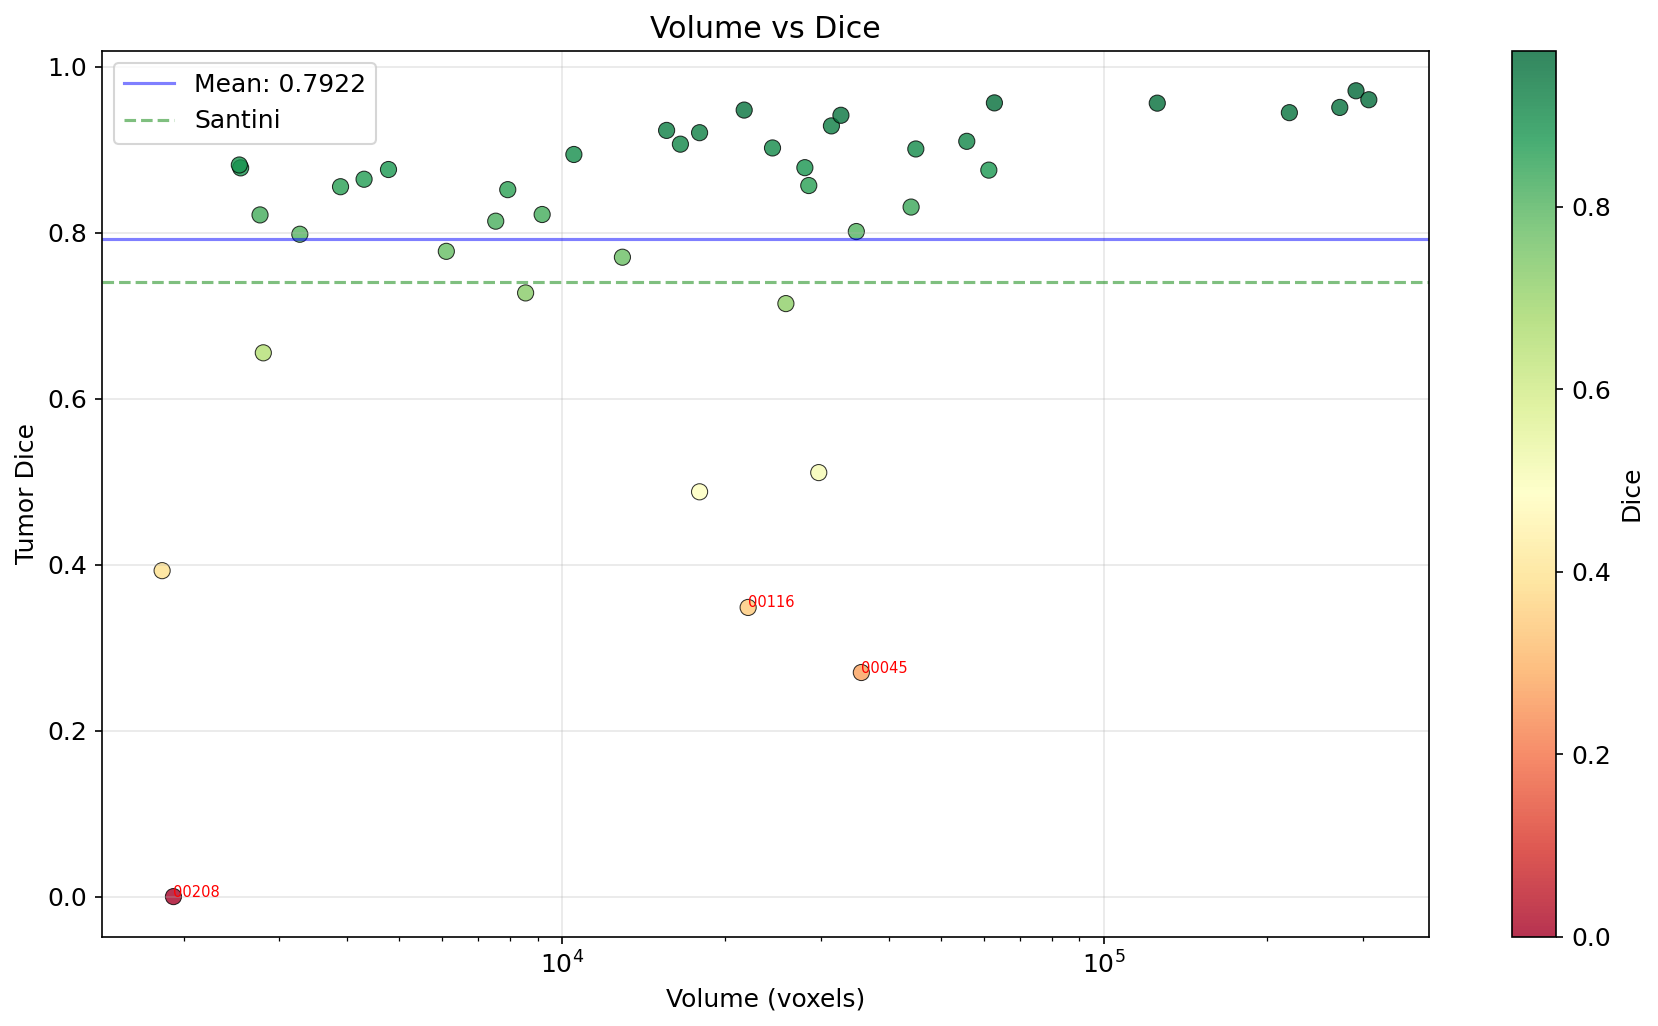

fig08


In [29]:
# Fig8
fig,ax=plt.subplots(figsize=(12,7)); vols=[r['tumor_voxels'] for r in all_results]; dices=[r['tumor']['dice'] for r in all_results]
sc=ax.scatter(vols,dices,c=dices,cmap='RdYlGn',s=60,edgecolors='black',lw=0.5,alpha=0.8); plt.colorbar(sc,label='Dice')
for r in all_results:
  if r['tumor']['dice']<0.35: ax.annotate(r['case_name'].replace('case_',''),(r['tumor_voxels'],r['tumor']['dice']),fontsize=7,color='red')
ax.set_xlabel('Volume (voxels)'); ax.set_ylabel('Tumor Dice'); ax.set_title('Volume vs Dice'); ax.set_xscale('log')
ax.axhline(np.mean(dices),color='blue',ls='-',alpha=0.5,label=f'Mean: {np.mean(dices):.4f}')
ax.axhline(0.740,color='green',ls='--',alpha=0.5,label='Santini'); ax.legend(); ax.grid(True,alpha=0.3)
plt.tight_layout(); plt.savefig(FIG_DIR/'fig08_size_vs_dice.png'); plt.show()
print('fig08')

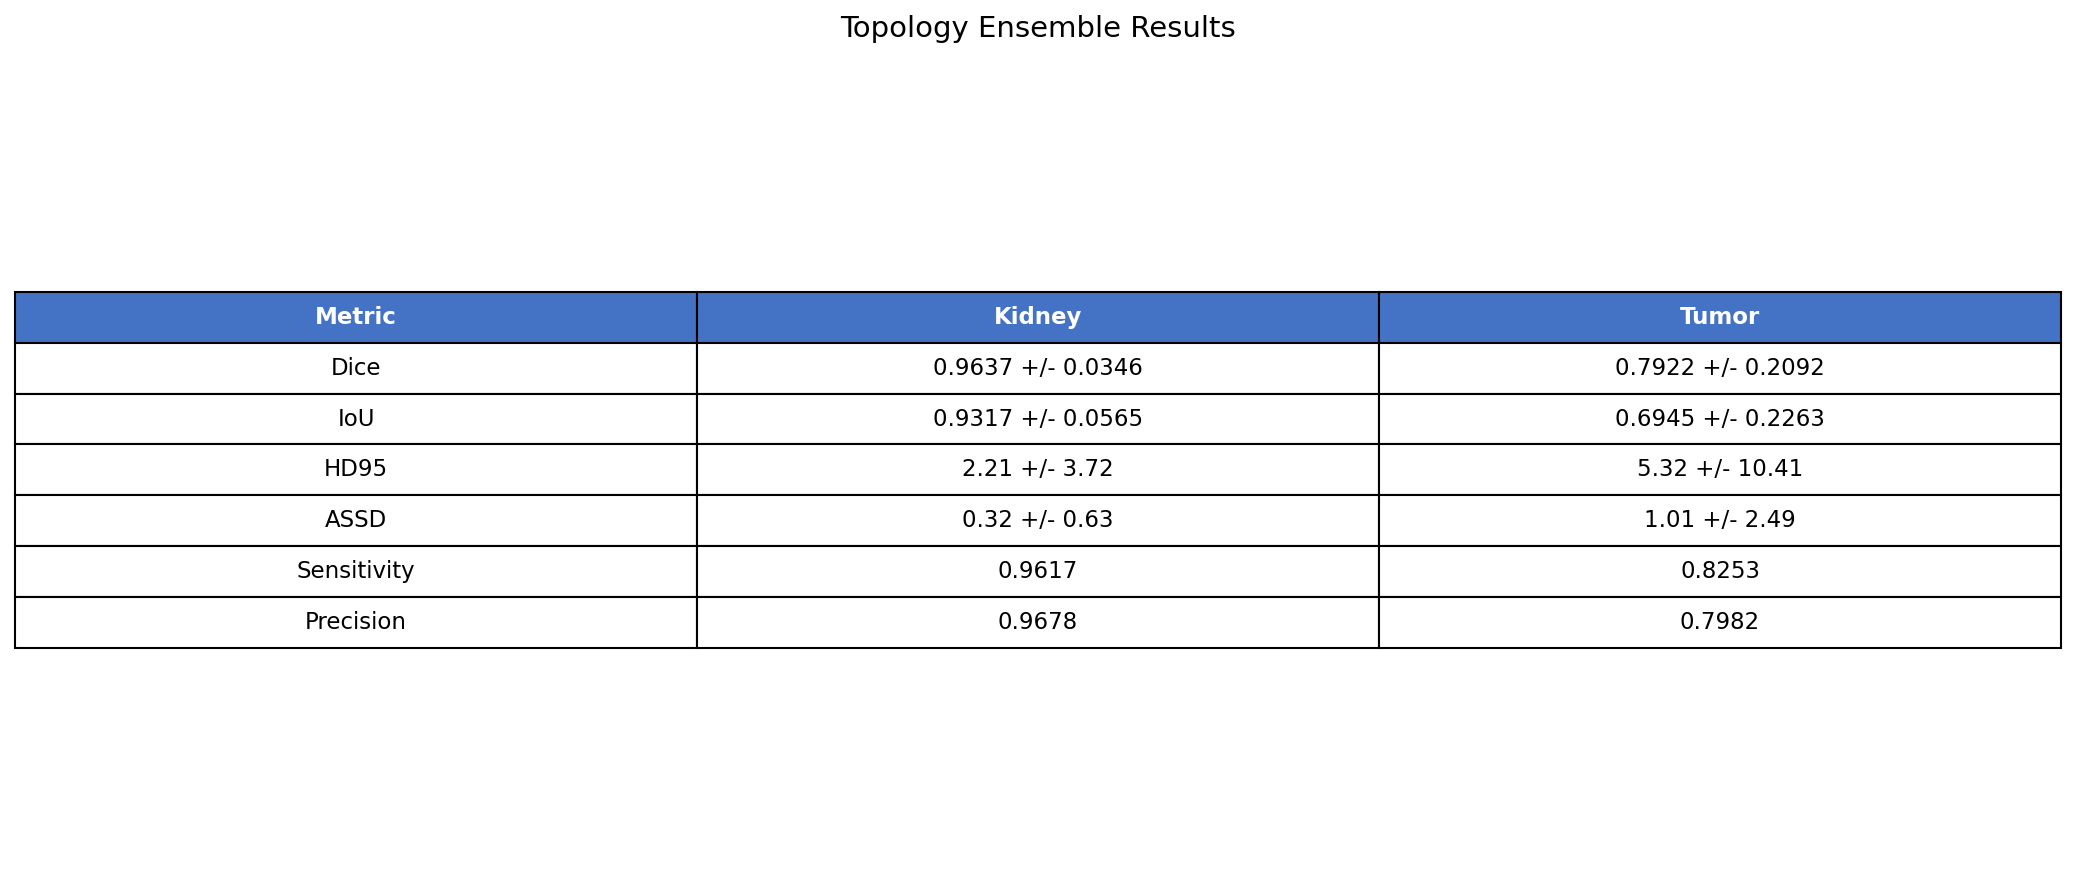

fig09


In [30]:
# Fig9
s=s_all; fig,ax=plt.subplots(figsize=(14,6)); ax.axis('off')
td=[['Metric','Kidney','Tumor'],
  ['Dice',f"{s['kidney_dice']['mean']:.4f} +/- {s['kidney_dice']['std']:.4f}",f"{s['tumor_dice']['mean']:.4f} +/- {s['tumor_dice']['std']:.4f}"],
  ['IoU',f"{s['kidney_iou']['mean']:.4f} +/- {s['kidney_iou']['std']:.4f}",f"{s['tumor_iou']['mean']:.4f} +/- {s['tumor_iou']['std']:.4f}"],
  ['HD95',f"{s['kidney_hd95']['mean']:.2f} +/- {s['kidney_hd95']['std']:.2f}",f"{s['tumor_hd95']['mean']:.2f} +/- {s['tumor_hd95']['std']:.2f}"],
  ['ASSD',f"{s['kidney_assd']['mean']:.2f} +/- {s['kidney_assd']['std']:.2f}",f"{s['tumor_assd']['mean']:.2f} +/- {s['tumor_assd']['std']:.2f}"],
  ['Sensitivity',f"{s['kidney_sensitivity']['mean']:.4f}",f"{s['tumor_sensitivity']['mean']:.4f}"],
  ['Precision',f"{s['kidney_precision']['mean']:.4f}",f"{s['tumor_precision']['mean']:.4f}"]]
table=ax.table(cellText=td[1:],colLabels=td[0],loc='center',cellLoc='center')
table.auto_set_font_size(False); table.set_fontsize(11); table.scale(1,1.8)
for j in range(3): table[0,j].set_facecolor('#4472C4'); table[0,j].set_text_props(color='white',fontweight='bold')
ax.set_title('Topology Ensemble Results',fontsize=14,pad=20)
plt.tight_layout(); plt.savefig(FIG_DIR/'fig09_comparison.png'); plt.show()
print('fig09')

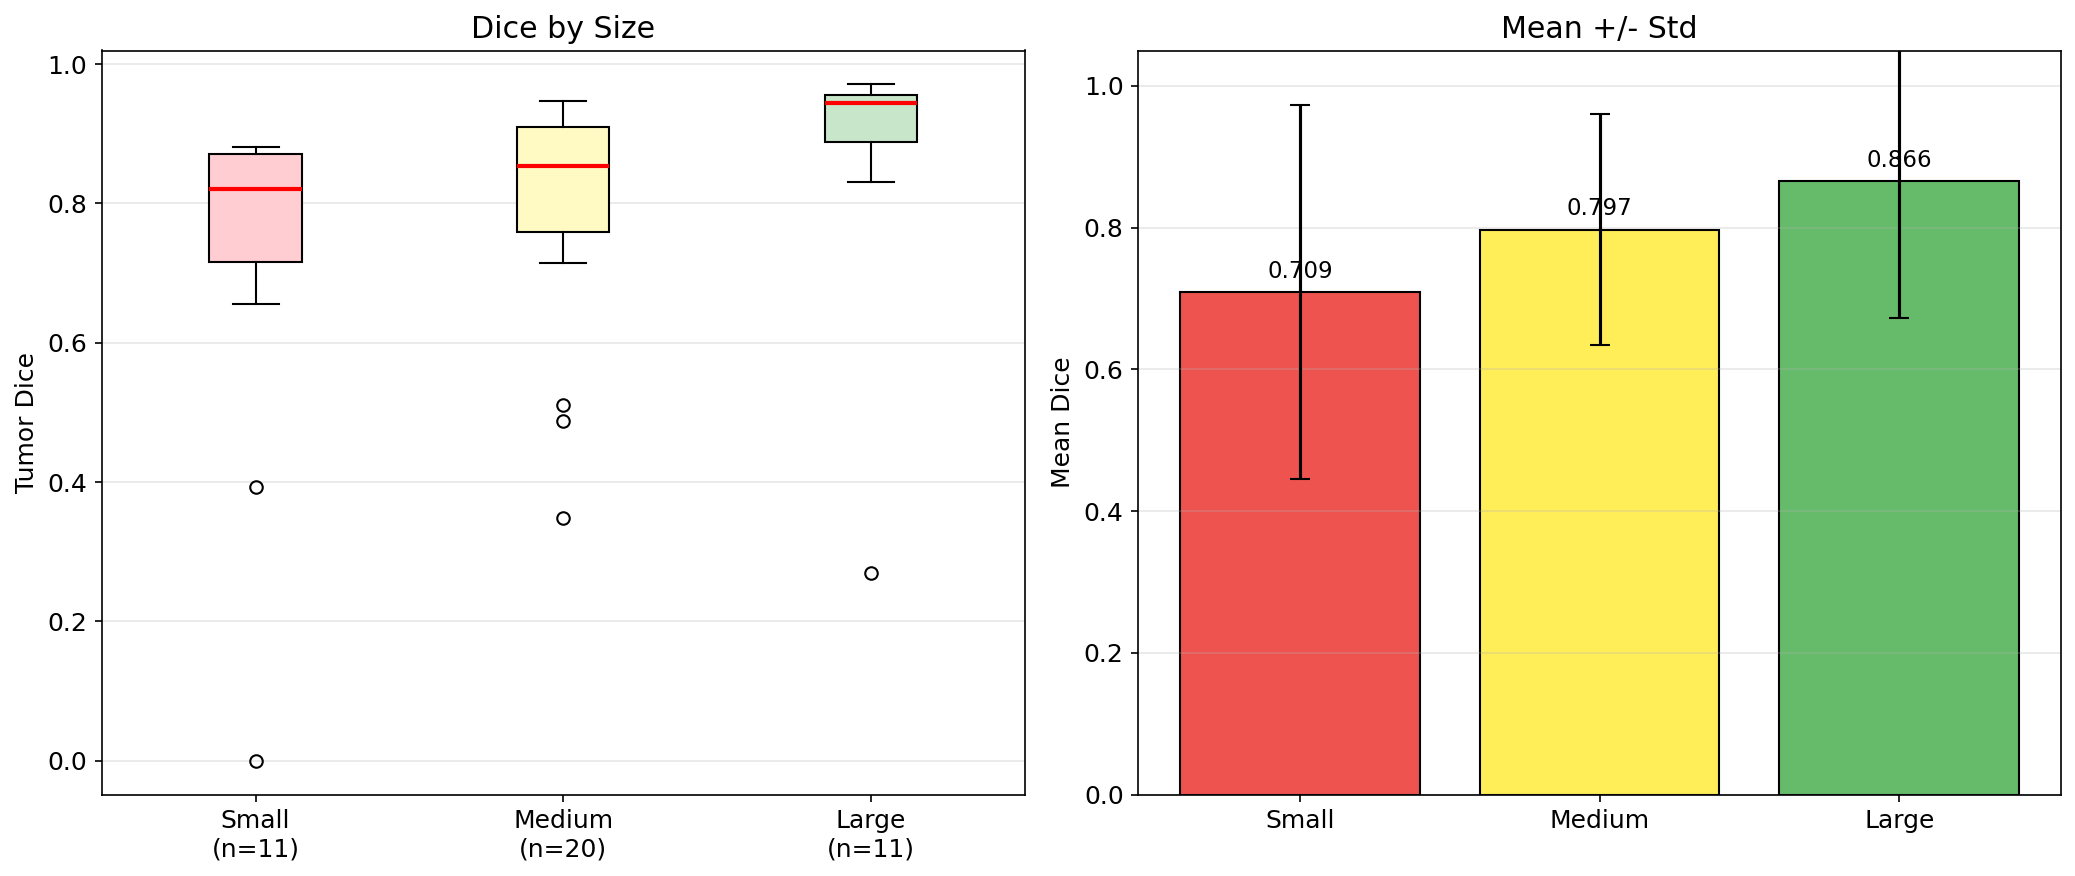

fig10


In [31]:
# Fig10
vols=[r['tumor_voxels'] for r in all_results]; p25=np.percentile(vols,25); p75=np.percentile(vols,75)
sm=[r for r in all_results if r['tumor_voxels']<p25]; md_c=[r for r in all_results if p25<=r['tumor_voxels']<p75]; lg=[r for r in all_results if r['tumor_voxels']>=p75]
sd=[r['tumor']['dice'] for r in sm]; mdd=[r['tumor']['dice'] for r in md_c]; ld=[r['tumor']['dice'] for r in lg]
fig,(a1,a2)=plt.subplots(1,2,figsize=(14,6))
bp=a1.boxplot([sd,mdd,ld],labels=[f'Small\n(n={len(sm)})',f'Medium\n(n={len(md_c)})',f'Large\n(n={len(lg)})'],patch_artist=True,medianprops=dict(color='red',lw=2))
bp['boxes'][0].set_facecolor('#ffcdd2'); bp['boxes'][1].set_facecolor('#fff9c4'); bp['boxes'][2].set_facecolor('#c8e6c9')
a1.set_ylabel('Tumor Dice'); a1.set_title('Dice by Size'); a1.grid(axis='y',alpha=0.3)
means=[np.mean(sd),np.mean(mdd),np.mean(ld)]; stds=[np.std(sd),np.std(mdd),np.std(ld)]
bars=a2.bar(['Small','Medium','Large'],means,yerr=stds,color=['#ef5350','#ffee58','#66bb6a'],edgecolor='black',capsize=5)
a2.set_ylabel('Mean Dice'); a2.set_title('Mean +/- Std'); a2.set_ylim([0,1.05]); a2.grid(axis='y',alpha=0.3)
for b,m in zip(bars,means): a2.text(b.get_x()+b.get_width()/2,b.get_height()+0.02,f'{m:.3f}',ha='center',fontsize=11)
plt.tight_layout(); plt.savefig(FIG_DIR/'fig10_size_stratified.png'); plt.show()
print('fig10')

## 7. CSV Export

In [32]:
csv_path=RESULTS_DIR/'nb05h_ensemble_results.csv'
with open(csv_path,'w',newline='') as f:
  w=csv.writer(f)
  w.writerow(['case','tvox','anomaly','kid_dice','kid_iou','kid_hd95','kid_assd','kid_sens','kid_prec','tum_dice','tum_iou','tum_hd95','tum_assd','tum_sens','tum_prec','uncertainty'])
  for r in all_results:
    km=r['kidney_merged']; tm=r['tumor']
    w.writerow([r['case_name'],r['tumor_voxels'],r['is_anomaly'],
      f"{km['dice']:.4f}",f"{km['iou']:.4f}",f"{km['hd95']:.2f}" if not np.isnan(km['hd95']) else 'NaN',
      f"{km['assd']:.2f}" if not np.isnan(km['assd']) else 'NaN',f"{km['sensitivity']:.4f}",f"{km['precision']:.4f}",
      f"{tm['dice']:.4f}",f"{tm['iou']:.4f}",f"{tm['hd95']:.2f}" if not np.isnan(tm['hd95']) else 'NaN',
      f"{tm['assd']:.2f}" if not np.isnan(tm['assd']) else 'NaN',f"{tm['sensitivity']:.4f}",f"{tm['precision']:.4f}",
      f"{r['uncertainty_score']:.4f}"])
print(f'CSV: {csv_path}')

CSV: D:\fsdf_uca_kits\outputs\results_80_20\nb05h_ensemble_results.csv


## 8. Final Summary

In [33]:
s=s_all; se=s_excl
print(f"\n{'='*70}")
print(f"FINAL THESIS RESULTS")
print(f"{'='*70}")
print(f"  Architecture: FSDF-UCA-Net V7")
print(f"    SliceAttentionGate + TumorAwareHead + scSE Decoder")
print(f"    + ASPP + CBAM + BW-EDL + Focal Tversky + Hard Curriculum")
print(f"  Inference: Topology-Guided Fusion (V5 seed + V5+V6+V7 growth)")
print(f"  V5 ep{ck5['epoch']}, V6 ep{ck6['epoch']}, V7 ep{ck7['epoch']}")
print()
print(f"  PRIMARY ({s['n_tumor']} cases):")
print(f"    Kidney (KiTS):   {s['kidney_dice']['mean']:.4f} +/- {s['kidney_dice']['std']:.4f}")
print(f"    Tumor Dice:      {s['tumor_dice']['mean']:.4f} +/- {s['tumor_dice']['std']:.4f}")
print(f"    Tumor Median:    {s['tumor_dice']['median']:.4f}")
print(f"    Tumor HD95:      {s['tumor_hd95']['mean']:.2f} +/- {s['tumor_hd95']['std']:.2f} mm")
print(f"    Tumor ASSD:      {s['tumor_assd']['mean']:.2f} +/- {s['tumor_assd']['std']:.2f} mm")
print(f"    Sensitivity:     {s['tumor_sensitivity']['mean']:.4f}")
print(f"    Precision:       {s['tumor_precision']['mean']:.4f}")
print(f"    ECE:             {ece:.4f}")
print()
print(f"  EXCLUDING ANOMALIES ({se['n_tumor']} cases):")
print(f"    Tumor Dice:      {se['tumor_dice']['mean']:.4f} +/- {se['tumor_dice']['std']:.4f}")
print(f"    Tumor Median:    {se['tumor_dice']['median']:.4f}")
print()
print(f"  vs PUBLISHED:")
print(f"    Santini 2.5D:    0.740 -> Ours {s['tumor_dice']['mean']:.4f} (+{s['tumor_dice']['mean']-0.740:.3f})")
print(f"    Santini (excl.):          Ours {se['tumor_dice']['mean']:.4f} (+{se['tumor_dice']['mean']-0.740:.3f})")
print()
for i,n in enumerate(['tumor_dice_bar','best_avg_worst','cbam_attention','rejection_curve','ece','unc_vs_dice','boxplots','size_vs_dice','comparison','size_stratified'],1):
    print(f"  fig{i:02d}_{n}.png")
with open(RESULTS_DIR/'nb05h_final_comprehensive.json','w') as f:
    json.dump({'model':'Topology Ensemble V5+V6+V7','primary':{'n':s['n_tumor'],'kidney':s['kidney_dice']['mean'],
        'tumor':s['tumor_dice']['mean'],'tumor_median':s['tumor_dice']['median'],'ece':ece},
        'excl_anomaly':{'n':se['n_tumor'],'tumor':se['tumor_dice']['mean']},
        'per_case':all_results},f,indent=2,default=str)
print(f"\nJSON saved.")


FINAL THESIS RESULTS
  Architecture: FSDF-UCA-Net V7
    SliceAttentionGate + TumorAwareHead + scSE Decoder
    + ASPP + CBAM + BW-EDL + Focal Tversky + Hard Curriculum
  Inference: Topology-Guided Fusion (V5 seed + V5+V6+V7 growth)
  V5 ep63, V6 ep60, V7 ep54

  PRIMARY (42 cases):
    Kidney (KiTS):   0.9637 +/- 0.0346
    Tumor Dice:      0.7922 +/- 0.2092
    Tumor Median:    0.8698
    Tumor HD95:      5.32 +/- 10.41 mm
    Tumor ASSD:      1.01 +/- 2.49 mm
    Sensitivity:     0.8253
    Precision:       0.7982
    ECE:             0.0121

  EXCLUDING ANOMALIES (41 cases):
    Tumor Dice:      0.8115 +/- 0.1707
    Tumor Median:    0.8753

  vs PUBLISHED:
    Santini 2.5D:    0.740 -> Ours 0.7922 (+0.052)
    Santini (excl.):          Ours 0.8115 (+0.072)

  fig01_tumor_dice_bar.png
  fig02_best_avg_worst.png
  fig03_cbam_attention.png
  fig04_rejection_curve.png
  fig05_ece.png
  fig06_unc_vs_dice.png
  fig07_boxplots.png
  fig08_size_vs_dice.png
  fig09_comparison.png
  fig10_